# Исследовательский анализ заведений общественного питания в Москве

# Цели и задачи проекта

**Цель проекта:**
Предоставить потенциальным инвесторам объективные данные для принятия решения об открытии заведения в Москве. На основе аналитики рынка общественного питания определить оптимальные параметры будущего бизнеса: тип (кафе, ресторан, бар), локацию, ценовой сегмент и концепцию.

**Ключевые задачи:**

1. **Загрузка и первичный анализ данных:** Обработка информации о заведениях Москвы (категория, адрес, рейтинг, сетевой признак, посадочные места, средний чек).

2. **Подготовка данных:** Очистка датасета от дубликатов и ошибок, преобразование форматов, заполнение пропусков и генерация новых признаков (например, флаг «круглосуточно»).

3. **Исследование рынка (EDA):** Выявление основных трендов, закономерностей и структуры рынка общественного питания столицы.

4. **Разработка рекомендаций:** Формирование итоговых выводов и практических советов для инвесторов по выбору формата и места открытия.

# Описание данных

Для анализа поступили данные о клиентах банка «Метанпром». Данные состоят из двух датасетов:

- `rest_info.csv` — информация об использовании клиентом услуг банка;
- `rest_price.csv` —  персональная информация клиентов.

### Описание датасета `rest_info`

Файл `/datasets/rest_info.csv` содержит информацию о заведениях общественного питания:

- `id` — уникальный идентификатор завдения;
- `name` — название заведения;
- `address` — адрес заведения;
- `district` — административный район, в котором находится заведение, например Центральный административный округ;
- `category` — категория заведения, например «кафе», «пиццерия» или «кофейня»;
- `hours` — информация о днях и часах работы;
- `rating` — рейтинг заведения по оценкам пользователей в Яндекс Картах (высшая оценка — `5.0`);
- `chain` — число, выраженное 0 или 1, которое показывает, является ли заведение сетевым (для маленьких сетей могут встречаться ошибки):
    * `0` — заведение не является сетевым;
    * `1` — заведение является сетевым.;
- `seats` — количество посадочных мест.

### Описание датасета `rest_price`

Файл `/datasets/rest_price.csv` содержит информацию о среднем чеке в заведениях общественного питания:

- `id` — уникальный идентификатор завдения;
- `price` —  категория цен в заведении, например «средние», «ниже среднего», «выше среднего» и так далее;
- `avg_bill` — строка, которая хранит среднюю стоимость заказа в виде диапазона, например
    * «Средний счёт: 1000–1500 ₽»;
    * «Цена чашки капучино: 130–220 ₽»;
    * «Цена бокала пива: 400–600 ₽».
    * и так далее;;
- `middle_avg_bill` — число с оценкой среднего чека, которое указано только для значений из столбца `avg_bill`, начинающихся с подстроки «Средний счёт»
    * Если в строке указан ценовой диапазон из двух значений, в столбец войдёт медиана этих двух значений.
    * Если в строке указано одно число — цена без диапазона, то в столбец войдёт это число.
    * Если значения нет или оно не начинается с подстроки «Средний счёт», то в столбец ничего не войдёт.;
- `middle_coffee_cup` — число с оценкой одной чашки капучино, которое указано только для значений из столбца avg_bill, начинающихся с подстроки «Цена одной чашки капучино»:
    * Если в строке указан ценовой диапазон из двух значений, в столбец войдёт медиана этих двух значений.
    * Если в строке указано одно число — цена без диапазона, то в столбец войдёт это число.
    * Если значения нет или оно не начинается с подстроки «Цена одной чашки капучино», то в столбец ничего не войдёт.

# Содержимое проекта

---
* **Шаг 1. Загрузка данных и знакомство с ними**
  - Загрузка датасетов `rest_info.csv` и `rest_price.csv`, первичный анализ структуры, объёма, типов данных, наличия пропусков.
* **Шаг 2. Предобработка данных**
  - Корректировка типов, обработка пропусков, удаление дубликатов, создание столбца `is_24_7` (круглосуточный режим работы).
* **Шаг 3. Исследовательский анализ данных**
  - 3.1 Анализ категорий заведений и их количества.
  - 3.2 Распределение заведений по административным районам Москвы, отдельный анализ ЦАО.
  - 3.3 Соотношение сетевых и несетевых заведений в целом и по категориям.
  - 3.4 Исследование количества посадочных мест, выявление аномалий и типичных значений для каждой категории.
  - 3.5 Анализ рейтингов заведений, сравнение по категориям.
  - 3.6 Изучение корреляции рейтинга с другими признаками (категория, район, сетевость, число мест, ценовая категория, круглосуточность).
  - 3.7 Выявление топ-15 популярных сетей по числу заведений и анализ их среднего рейтинга.
  - 3.8 Изучение зависимости среднего чека (`middle_avg_bill`) от района расположения, сравнение центра и периферии.
* **Шаг 4. Итоговый вывод и рекомендации**
  - Обобщение ключевых результатов, формулировка рекомендаций для инвесторов относительно формата, локации, ценовой политики и других аспектов будущего заведения.

## Шаг. Загрузка данных и знакомство с ними


In [1]:
!pip install phik -q

In [2]:
# Импортируем библиотеки
import pandas as pd

# Загружаем библиотеки для визуализации данных
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Загружаем библиотеку для расчёта коэффициента корреляции phi_k
from phik import phik_matrix

In [3]:
# Загружаем данные о заведениях и среднем чеке
catering_df = pd.read_csv('https://code.s3.yandex.net/datasets/rest_info.csv')
cheque_df = pd.read_csv('https://code.s3.yandex.net/datasets/rest_price.csv')

Познакомимся с данными датасета `rest_info.csv` — выведем первые строки методом `head()`, а информацию о датафрейме методом `info()`:

In [4]:
# Выводим первые строки датафрейма на экран
catering_df.head()

,id,name,category,address,district,hours,rating,chain,seats
0,0c3e3439a8c64ea5bf6ecd6ca6ae19f0,WoWфли,кафе,"Москва, улица Дыбенко, 7/1",Северный административный округ,"ежедневно, 10:00–22:00",5.0,0,NaN
1,045780ada3474c57a2112e505d74b633,Четыре комнаты,ресторан,"Москва, улица Дыбенко, 36, корп. 1",Северный административный округ,"ежедневно, 10:00–22:00",4.5,0,4.0
2,1070b6b59144425896c65889347fcff6,Хазри,кафе,"Москва, Клязьминская улица, 15",Северный административный округ,"пн-чт 11:00–02:00; пт,сб 11:00–05:00; вс 11:00...",4.6,0,45.0
3,03ac7cd772104f65b58b349dc59f03ee,Dormouse Coffee Shop,кофейня,"Москва, улица Маршала Федоренко, 12",Северный административный округ,"ежедневно, 09:00–22:00",5.0,0,NaN
4,a163aada139c4c7f87b0b1c0b466a50f,Иль Марко,пиццерия,"Москва, Правобережная улица, 1Б",Северный административный округ,"ежедневно, 10:00–22:00",5.0,1,148.0


In [5]:
# Выводим информацию о датафрейме
catering_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8406 entries, 0 to 8405
Data columns (total 9 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        8406 non-null   object 
 1   name      8406 non-null   object 
 2   category  8406 non-null   object 
 3   address   8406 non-null   object 
 4   district  8406 non-null   object 
 5   hours     7870 non-null   object 
 6   rating    8406 non-null   float64
 7   chain     8406 non-null   int64  
 8   seats     4795 non-null   float64
dtypes: float64(2), int64(1), object(6)
memory usage: 591.2+ KB


Датасет `rest_info.csv` содержит 9 столбцов и 8406 строк, в которых представлена информация об объектах общественного питания.

После первичного анализа можно сделать следующие выводы:

- названия столбцов приведены к нужному формату.
- значения в столбцах `id`, `name`, `category`, `address`, `district`, `hours` хранятся в типе данных `object`; `rating` и `seats` — `float64`; `chain` — `int64`. Размерность числовых данных можно оптимизировать.
- Пропуски содержатся только столбцах `hours` и `seats`.
- Судя по первому знакомству с данными, значения в столбцах соответствуют своему описанию.

Познакомимся с данными датасета `rest_price.csv` — выведем первые строки методом `head()`, а информацию о датафрейме методом `info()`:

In [6]:
# Выводим первые строки датафрейма на экран
cheque_df.head()

,id,price,avg_bill,middle_avg_bill,middle_coffee_cup
0,045780ada3474c57a2112e505d74b633,выше среднего,Средний счёт:1500–1600 ₽,1550.0,NaN
1,1070b6b59144425896c65889347fcff6,средние,Средний счёт:от 1000 ₽,1000.0,NaN
2,03ac7cd772104f65b58b349dc59f03ee,NaN,Цена чашки капучино:155–185 ₽,NaN,170.0
3,a163aada139c4c7f87b0b1c0b466a50f,средние,Средний счёт:400–600 ₽,500.0,NaN
4,8a343546b24e4a499ad96eb7d0797a8a,средние,NaN,NaN,NaN


In [7]:
# Выводим информацию о датафрейме
cheque_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4058 entries, 0 to 4057
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 4058 non-null   object 
 1   price              3315 non-null   object 
 2   avg_bill           3816 non-null   object 
 3   middle_avg_bill    3149 non-null   float64
 4   middle_coffee_cup  535 non-null    float64
dtypes: float64(2), object(3)
memory usage: 158.6+ KB


Датасет `rest_price.csv` содержит 5 столбцов и 4058 строк, в которых представлена информация о среднем чеке в заведениях общепита.

По аналогии с предыдущим датасетом можно отметить, что:
- названия столбцов приведены к нужному формату: `id`, `price`, `avg_bill` — `object`, `middle_avg_bill`, `middle_coffee_cup` - `float64`.
- числовые типа данных можно оптимизировать с понижением размерности. 
- есть пропуски в столбцах `price`, `avg_bill`, `middle_avg_bill`, `middle_coffee_cup`.
- значения в столбцах соответствуют описанию.
- первичное знакомство показывает, что данные соответствуют описанию и выглядят корректными. 

### Подготовка единого датафрейма

In [8]:
# ОБЪЕДИНИМ ДАТАСЕТЫ В ОДИН

data = pd.merge(catering_df, cheque_df, on='id', how='left')

In [9]:
# Выводим первые строки датафрейма на экран
data.head()

,id,name,category,address,district,hours,rating,chain,seats,price,avg_bill,middle_avg_bill,middle_coffee_cup
0,0c3e3439a8c64ea5bf6ecd6ca6ae19f0,WoWфли,кафе,"Москва, улица Дыбенко, 7/1",Северный административный округ,"ежедневно, 10:00–22:00",5.0,0,NaN,NaN,NaN,NaN,NaN
1,045780ada3474c57a2112e505d74b633,Четыре комнаты,ресторан,"Москва, улица Дыбенко, 36, корп. 1",Северный административный округ,"ежедневно, 10:00–22:00",4.5,0,4.0,выше среднего,Средний счёт:1500–1600 ₽,1550.0,NaN
2,1070b6b59144425896c65889347fcff6,Хазри,кафе,"Москва, Клязьминская улица, 15",Северный административный округ,"пн-чт 11:00–02:00; пт,сб 11:00–05:00; вс 11:00...",4.6,0,45.0,средние,Средний счёт:от 1000 ₽,1000.0,NaN
3,03ac7cd772104f65b58b349dc59f03ee,Dormouse Coffee Shop,кофейня,"Москва, улица Маршала Федоренко, 12",Северный административный округ,"ежедневно, 09:00–22:00",5.0,0,NaN,NaN,Цена чашки капучино:155–185 ₽,NaN,170.0
4,a163aada139c4c7f87b0b1c0b466a50f,Иль Марко,пиццерия,"Москва, Правобережная улица, 1Б",Северный административный округ,"ежедневно, 10:00–22:00",5.0,1,148.0,средние,Средний счёт:400–600 ₽,500.0,NaN


In [10]:
# Выводим данных нового датасета
data.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 8406 entries, 0 to 8405
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 8406 non-null   object 
 1   name               8406 non-null   object 
 2   category           8406 non-null   object 
 3   address            8406 non-null   object 
 4   district           8406 non-null   object 
 5   hours              7870 non-null   object 
 6   rating             8406 non-null   float64
 7   chain              8406 non-null   int64  
 8   seats              4795 non-null   float64
 9   price              3315 non-null   object 
 10  avg_bill           3816 non-null   object 
 11  middle_avg_bill    3149 non-null   float64
 12  middle_coffee_cup  535 non-null    float64
dtypes: float64(4), int64(1), object(8)
memory usage: 919.4+ KB


## Предобработка данных


In [11]:
# Проверка, есть ли дробные значения в seats
non_fract_seats = data['seats'].dropna()[data['seats'].dropna() % 1 != 0]
non_fract_seats

Series([], Name: seats, dtype: float64)

Дробных нет, идем дальше.

In [12]:
# Создание список из столбцов, которые нужно будет перевести к float32
columns_float_to_convert = [
    'rating',
    'middle_avg_bill',
    'middle_coffee_cup'
]
# Приведение столбцов к float с понижением битности до 32
data[columns_float_to_convert] = data[columns_float_to_convert].apply(lambda x: pd.to_numeric(x, errors='coerce', downcast='float'))

In [13]:
# Приведение столбца seats к Int64

data['seats'] = pd.to_numeric(data['seats'], errors='coerce').astype('Int64')

In [14]:
# Приведение столбца chain к int с понижением битности до 8

data['chain'] = data['chain'].astype('int8')

In [15]:
# Выведем данные отредактированного датасета

data.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 8406 entries, 0 to 8405
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 8406 non-null   object 
 1   name               8406 non-null   object 
 2   category           8406 non-null   object 
 3   address            8406 non-null   object 
 4   district           8406 non-null   object 
 5   hours              7870 non-null   object 
 6   rating             8406 non-null   float32
 7   chain              8406 non-null   int8   
 8   seats              4795 non-null   Int64  
 9   price              3315 non-null   object 
 10  avg_bill           3816 non-null   object 
 11  middle_avg_bill    3149 non-null   float32
 12  middle_coffee_cup  535 non-null    float32
dtypes: Int64(1), float32(3), int8(1), object(8)
memory usage: 771.6+ KB


In [16]:
# Также можно посмотреть описательную статистику для числовых столбцов
data.describe()

,rating,chain,seats,middle_avg_bill,middle_coffee_cup
count,8406.000000,8406.000000,4795.000000,3149.000000,535.000000
mean,4.229895,0.381275,108.421689,958.053650,174.721497
std,0.470348,0.485729,122.833396,1009.732849,88.951103
min,1.000000,0.000000,0.000000,0.000000,60.000000
25%,4.100000,0.000000,40.000000,375.000000,124.500000
50%,4.300000,0.000000,75.000000,750.000000,169.000000
75%,4.400000,1.000000,140.000000,1250.000000,225.000000
max,5.000000,1.000000,1288.000000,35000.000000,1568.000000


 Здесь мы видим большой разброс в данных между медианными и средними значениями для столбцов `mean`, `seats`, `middle_avg_bil`. Это свидетельствует о неравномерности распределения данных в этих столбцах, а также о наличии выбросов. 

In [17]:
# Изучим пропущенные значения

# Применяем метод isna() к датафрейму data
data.isna().sum()

id                      0
name                    0
category                0
address                 0
district                0
hours                 536
rating                  0
chain                   0
seats                3611
price                5091
avg_bill             4590
middle_avg_bill      5257
middle_coffee_cup    7871
dtype: int64

In [18]:
#Выведем таблицу со значением доли пропусков в абсолютном и относительном значении

missing_table = pd.DataFrame({
    'Количество пропусков': data.isnull().sum(),
    'Доля пропусков (%)': (data.isnull().mean() * 100).round(2)
})

missing_table = missing_table.sort_values('Количество пропусков', ascending=False)
missing_table

,Количество пропусков,Доля пропусков (%)
middle_coffee_cup,7871,93.64
middle_avg_bill,5257,62.54
price,5091,60.56
avg_bill,4590,54.60
seats,3611,42.96
hours,536,6.38
id,0,0.00
name,0,0.00
category,0,0.00
address,0,0.00


In [19]:
def show_missing_stats(df):
    """Статистика пропущенных значений по столбцам."""
    stats = pd.DataFrame({
        'Кол-во пропусков': df.isnull().sum(),
        'Доля пропусков': df.isnull().mean()
    })
    stats = stats[stats['Кол-во пропусков'] > 0]
    if stats.empty:
        return 'Пропусков в данных нет'
    return stats.style.format({'Доля пропусков': '{:.4f}'}).background_gradient(cmap='coolwarm')

show_missing_stats(data)

,Кол-во пропусков,Доля пропусков
hours,536,0.0638
seats,3611,0.4296
price,5091,0.6056
avg_bill,4590,0.5460
middle_avg_bill,5257,0.6254
middle_coffee_cup,7871,0.9364


 Столбцы `seats`, `price`, `avg_bill`, `middle_avg_bill` имеют пропуски одного порядка (от 43% до 63%). В столбце `middle_coffee_cup` — 94% значений отсутствуют.

**1. Пропуски в price (61%) и avg_bill (55%)**

Эти столбцы тесно связаны, поэтому причины у них общие.

Основная причина: Отсутствие информации в самом источнике или ее неверифицированный характер.

Владельцы не указали цену: На страницах заведений в Яндекс Бизнесе информация о среднем чеке или ценовой категории часто заполняется добровольно. Многие заведения (особенно небольшие или новые) могли просто не заполнить этот раздел.

Размытость понятия: Для некоторых заведений сложно однозначно определить "средний чек". Например, в столовой или ресторане при отеле ценовой диапазон может быть слишком широк, и владельцы избегают указывать конкретную вилку цен, чтобы не отпугивать посетителей.

Технические ошибки сбора данных: При автоматическом сборе данных с карт информация могла быть не считана, если она была представлена в нестандартном формате, отличном от шаблонов, которые ожидал парсер.

**2. Пропуски в middle_avg_bill (63%)**

Этот столбец — производная от avg_bill.

Основная причина: Структура исходного столбца avg_bill.
Пропуски здесь возникают строго потому, что в строке avg_bill не было подстроки «Средний счёт».

Вместо этого там могли быть фразы: «Цена чашки капучино: 130–220 ₽» или «Цена бокала пива: 400–600 ₽».

Это означает, что Яндекс Карты не смогли определить "средний чек" для данного типа заведения (например, для кофейни или бара логичнее указывать цену за чашку/бокал, а не за полноценный прием пищи).

**3. Пропуски в middle_coffee_cup (94%)**

Здесь самый высокий процент пропусков, и это логично.

Основная причина: Специфика заведений.

Это поле заполнялось только для тех заведений, которые в первую очередь ассоциируются с кофе и указали это в описании.

Огромный пласт ресторанов, баров, столовых и пиццерий просто не имеют в своей строке avg_bill подстроки «Цена одной чашки капучино», поэтому для них middle_coffee_cup остается пустым. Они либо вообще не подают кофе, либо не считают цену на капучино своей основной ценовой характеристикой.

**4. Пропуски в seats (43%)**

Основная причина: Сложность сбора и верификации данных.

Отсутствие в открытых источниках: Количество посадочных мест — это не та информация, которую заведения обязаны публиковать на картах. Ее часто указывают в описании, но далеко не всегда.

Сезонность и летние веранды: У многих заведений есть летние веранды, которые добавляют посадочные места. Владельцы могли указывать общее количество мест (в помещении + на улице), только количество мест в помещении или не указывать вовсе, так как количество мест летом непостоянно.

Концепция "с собой" и фуд-корты: Для точек формата "кофе с собой", отделов в фуд-кортах (где посадочные места общие) или небольших ларьков с выпечкой просто отсутствует, и владельцы не заполняют это поле.

**5. Пропуски в hours (6%)**

Самый маленький процент пропусков, что хорошо.

Основная причина: Временные или технические факторы.

Новые заведения: Заведение могло недавно открыться, и часы работы еще не были внесены в справочник.

Нестабильный график: У некоторых точек (например, киосков или сезонных кофеен) может быть "плавающий" график, зависящий от погоды или потока людей, и они избегают указывать жесткое расписание.

In [20]:
# Проверим на явные и неявные дубликаты

# Создаем статистику по столбцам
stats_table = pd.DataFrame({
    'Уникальные_значения': data.nunique(),
    'Заполненные_значения': data.count()
})

# Сортируем по убыванию уникальных значений
stats_table_sorted = stats_table.sort_values('Уникальные_значения', ascending=False)

# Выводим результат
print("\nСтатистика по столбцам:")
stats_table_sorted


Статистика по столбцам:


,Уникальные_значения,Заполненные_значения
id,8406,8406
address,5753,8406
name,5614,8406
hours,1307,7870
avg_bill,897,3816
middle_avg_bill,230,3149
seats,229,4795
middle_coffee_cup,96,535
rating,41,8406
district,9,8406


Здесь примечательны повторы в столбцах `address` и `name`, что говорит о наличии сетевых заведений и заведений, расположенных по одному и тому же адресу. Столбец `chain` является категориальным, о чем мы знали на этапе знакомства с данным. Остальные столбцы (кроме `id`) носят статистические данные, которые мы впоследствии будем исследовать.

In [21]:
# Изучаем уникальные значения в колонках 
print("Уникальные значения в колонках:")
data['district'].unique()

Уникальные значения в жанрах:


array(['Северный административный округ',
       'Северо-Восточный административный округ',
       'Северо-Западный административный округ',
       'Западный административный округ',
       'Центральный административный округ',
       'Восточный административный округ',
       'Юго-Восточный административный округ',
       'Южный административный округ',
       'Юго-Западный административный округ'], dtype=object)

In [22]:
print("Уникальные значения в жанрах:")
data['category'].unique()

Уникальные значения в жанрах:


array(['кафе', 'ресторан', 'кофейня', 'пиццерия', 'бар,паб',
       'быстрое питание', 'булочная', 'столовая'], dtype=object)

In [23]:
print("Уникальные значения в жанрах:")
data['rating'].unique()

Уникальные значения в жанрах:


array([5. , 4.5, 4.6, 4.4, 4.7, 4.8, 4.3, 4.9, 4.2, 4.1, 4. , 3.8, 3.9,
       3.7, 3.6, 2.8, 2.7, 3.1, 1.5, 2. , 1.4, 3.3, 3.5, 3.2, 2.9, 3. ,
       3.4, 2.3, 2.2, 2.5, 2.6, 1.7, 1. , 1.1, 2.4, 1.3, 1.2, 2.1, 1.8,
       1.9, 1.6], dtype=float32)

In [24]:
print("Уникальные значения в жанрах:")
data['price'].unique()

Уникальные значения в жанрах:


array([nan, 'выше среднего', 'средние', 'высокие', 'низкие'], dtype=object)

Всего в датасете представлено 8 категорий заведений, 9 административных районов Москвы и 4 категории цен.

In [25]:
# Нормализация данных

# Приведём категории к нижнему регистру
data['address'] = data['address'].str.lower()
data['name'] = data['name'].str.lower()
data['hours'] = data['hours'].str.upper()

In [26]:
# Выведем количество уникальных значений для столбцов

unique_counts_sorted = data.nunique().sort_values(ascending=False)
print("\nОтсортировано по убыванию:")
unique_counts_sorted


Отсортировано по убыванию:


id                   8406
address              5752
name                 5512
hours                1307
avg_bill              897
middle_avg_bill       230
seats                 229
middle_coffee_cup      96
rating                 41
district                9
category                8
price                   4
chain                   2
dtype: int64

In [27]:
# Проверяем наличие явных дубликатов в данных
duplicate_rows = data[data.duplicated()]

In [28]:
# Выводим количество явных дубликатов
print("Количество явных дубликатов:")
duplicate_rows.shape[0]

Количество явных дубликатов:


0

In [29]:
# Проверяем неявные дубликаты
data.duplicated(subset=['name','address']).sum()

4

In [30]:
# Проверяем неявные дубликаты по столбцам name address
data[data.duplicated(subset=['name','address'], keep=False)]

,id,name,category,address,district,hours,rating,chain,seats,price,avg_bill,middle_avg_bill,middle_coffee_cup
189,072032ce16dc47bfbc63b672c75bd371,кафе,кафе,"москва, парк ангарские пруды",Северный административный округ,"ЕЖЕДНЕВНО, 09:00–23:00",3.2,0,<NA>,NaN,NaN,NaN,NaN
215,897ddbc6746c4388b19dc8a9fcdbb488,кафе,кафе,"москва, парк ангарские пруды",Северный административный округ,"ЕЖЕДНЕВНО, 10:00–22:00",3.2,0,<NA>,NaN,NaN,NaN,NaN
1430,62608690e9cc464fbcd980cfd552e334,more poke,ресторан,"москва, волоколамское шоссе, 11, стр. 2",Северный административный округ,"ЕЖЕДНЕВНО, 09:00–21:00",4.2,0,188,NaN,NaN,NaN,NaN
1511,a69f018d5c064873a3b491b0121bc1b4,more poke,ресторан,"москва, волоколамское шоссе, 11, стр. 2",Северный административный округ,"ПН-ЧТ 09:00–18:00; ПТ,СБ 09:00–21:00; ВС 09:00...",4.2,1,188,NaN,NaN,NaN,NaN
2211,c6ef39ae8a8c483d8f9a6531bc386a2c,раковарня клешни и хвосты,ресторан,"москва, проспект мира, 118",Северо-Восточный административный округ,"ЕЖЕДНЕВНО, 12:00–00:00",4.4,0,150,NaN,NaN,NaN,NaN
2420,aba1de7ad7d64ac0a3f8684bda29d905,раковарня клешни и хвосты,"бар,паб","москва, проспект мира, 118",Северо-Восточный административный округ,"ПН-ЧТ 12:00–00:00; ПТ,СБ 12:00–01:00; ВС 12:00...",4.4,1,150,NaN,NaN,NaN,NaN
3091,3c2a73ea79a04be48858fab3685f2f37,хлеб да выпечка,булочная,"москва, ярцевская улица, 19",Западный административный округ,"ЕЖЕДНЕВНО, 09:00–22:00",4.1,1,276,NaN,NaN,NaN,NaN
3109,d3116844e4e048f99614eb30be3214e0,хлеб да выпечка,кафе,"москва, ярцевская улица, 19",Западный административный округ,NaN,4.1,0,276,NaN,NaN,NaN,NaN


Есть  4 неявных дубликата

In [31]:
suspect_rows = data[data.duplicated(subset=['name', 'address'])]
suspect_rows[['name', 'address']]

,name,address
215,кафе,"москва, парк ангарские пруды"
1511,more poke,"москва, волоколамское шоссе, 11, стр. 2"
2420,раковарня клешни и хвосты,"москва, проспект мира, 118"
3109,хлеб да выпечка,"москва, ярцевская улица, 19"


In [32]:
# УДАДЛЕНИЕ ДУБЛИКАТОВ
data = data.drop_duplicates(subset=['name', 'address'], keep='first')

In [33]:
data.duplicated(subset=['name', 'address']).sum()

0

In [34]:
# Выведем и ознакомисся с данными столбца hours

data['hours'].head()

0                               ЕЖЕДНЕВНО, 10:00–22:00
1                               ЕЖЕДНЕВНО, 10:00–22:00
2    ПН-ЧТ 11:00–02:00; ПТ,СБ 11:00–05:00; ВС 11:00...
3                               ЕЖЕДНЕВНО, 09:00–22:00
4                               ЕЖЕДНЕВНО, 10:00–22:00
Name: hours, dtype: object

- Для дальнейшей работы создалим столбец `is_24_7` с обозначением того, что заведение работает ежедневно и круглосуточно, то есть 24/7:
  - логическое значение `True` — если заведение работает ежедневно и круглосуточно;
  - логическое значение `False` — в противоположном случае.

In [35]:
# Создадим новый столбец is_24_7

def is_24_7(hours):
    if pd.isna(hours):
        return False
    h = hours.upper()
    return 'ЕЖЕДНЕВНО' in h and any(t in h for t in [
        '00:00–00:00', '00:00-00:00', 'КРУГЛОСУТОЧНО', '24/7'
    ])

# Применяем упрощенную функцию
data['is_24_7'] = data['hours'].apply(is_24_7)
data['is_24_7'].head()

0    False
1    False
2    False
3    False
4    False
Name: is_24_7, dtype: bool

In [36]:
# Этот код даст полную картину
pd.DataFrame({
    'count': data['is_24_7'].value_counts(),
    'share_%': (data['is_24_7'].value_counts(normalize=True) * 100).round(2)
})

,count,share_%
False,7672,91.31
True,730,8.69


In [37]:
data['is_24_7'].value_counts()

False    7672
True      730
Name: is_24_7, dtype: int64

 По итогам проделанной работы  мы получили значения 730 строк, данные которых говорят о круглосуточной работе заведения (8,68%).

In [38]:
show_missing_stats(data)

,Кол-во пропусков,Доля пропусков
hours,535,0.0637
seats,3610,0.4297
price,5087,0.6055
avg_bill,4586,0.5458
middle_avg_bill,5253,0.6252
middle_coffee_cup,7867,0.9363


---

### Промежуточный вывод


- Проводя предобработку данные были выявлены пропуски в столбцах `seats`, `price`, `avg_bill`, `middle_avg_bill`(от 43% до 63%). В столбце `middle_coffee_cup` 94% значений отсутствуют.

- Во всех столбцах, кроме `id` наблюдаются повторы. Повторы в `address` означают наличие заведений, расположенных по одному адресу. Повторы в `name` говорят о наличии сетевых заведений или заведений с одинаковыми названиями.

- В датасете представлено 8 категорий заведений, 9 административных районов Москвы и 4 категории цен.

- Явных дубликатов в датасете не найдено.

- Есть 4 неявных дубликата

- 730 заведений из общего списка работают круглосуточно.

## Исследовательский анализ данных

---

### Задача 1

***Какие категории заведений представлены в данных? Исследуйте количество объектов общественного питания по каждой категории. Результат сопроводите подходящей визуализацией.***

In [39]:
# ВЫВЕДЕМ СНОВА ВСЕ УНИКАЛЬНЫЕ КАТЕГОРИИ

data['category'].unique()

array(['кафе', 'ресторан', 'кофейня', 'пиццерия', 'бар,паб',
       'быстрое питание', 'булочная', 'столовая'], dtype=object)

In [40]:
# КОЛИЧЕСТВО ОБЪЕКТОВ ПО КАЖДОЙ КАТЕГОРИИ

category_counts = data['category'].value_counts()
category_counts

кафе               2376
ресторан           2042
кофейня            1413
бар,паб             764
пиццерия            633
быстрое питание     603
столовая            315
булочная            256
Name: category, dtype: int64

In [41]:
# РАСПРЕДЕЛЕНИЕ КАТЕГОРИЙ ПО КОЛИЧЕСТВУ ЗАВЕДЕНИЙ

pd.DataFrame({
    'count': category_counts,
    'share_%': (category_counts / len(data) * 100).round(1)
}).head(10)

,count,share_%
кафе,2376,28.3
ресторан,2042,24.3
кофейня,1413,16.8
"бар,паб",764,9.1
пиццерия,633,7.5
быстрое питание,603,7.2
столовая,315,3.7
булочная,256,3.0


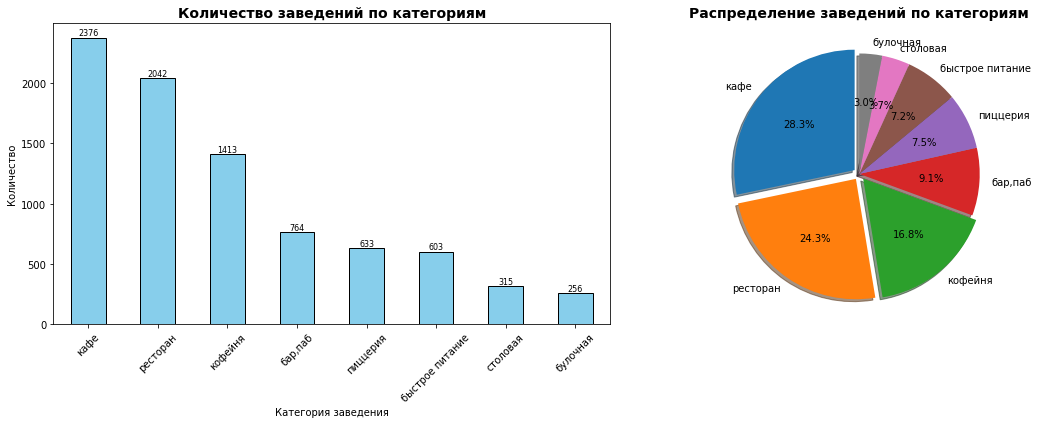

In [42]:
# ВИЗУАЛИЗАЦИЯ ДАННЫХ

# Создаем фигуру с графиками 
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# График 1: Столбчатая диаграмма (все категории)
ax1 = axes[0]
category_counts.sort_values(ascending=False).plot(
    kind='bar', 
    ax=ax1, 
    color='skyblue', 
    edgecolor='black'
)
ax1.set_title('Количество заведений по категориям', fontsize=14, fontweight='bold')
ax1.set_xlabel('Категория заведения')
ax1.set_ylabel('Количество')
ax1.tick_params(axis='x', rotation=45)

# Добавляем значения на столбцы
for i, v in enumerate(category_counts.sort_values(ascending=False).values):
    ax1.text(i, v + 0.5, str(v), ha='center', va='bottom', fontsize=8)

# График 2: Круговая диаграмма
ax2 = axes[1]
top_8 = category_counts.nlargest(8) # -------- Здесь и дальше использую заглушку для возможности выводить какой-то топ данных на случай необходимости "отрезать" мелкие значения для более наглядной визуализации
other_count = category_counts.sum() - top_8.sum()
if other_count > 0:
    plot_data = pd.concat([top_8, pd.Series({'Другие': other_count})])
else:
    plot_data = top_8

# Функция для отображения процентов
def autopct_func(pct):
    return f'{pct:.1f}%' if pct > 2 else ''

wedges, texts, autotexts = ax2.pie(
    plot_data.values, 
    labels=plot_data.index, 
    autopct=autopct_func,
    startangle=90,
    explode=[0.05 if i < 3 else 0 for i in range(len(plot_data))],  # Выделяем топ-3
    shadow=True
)
ax2.set_title('Распределение заведений по категориям', fontsize=14, fontweight='bold')

plt.tight_layout()
plt.show()

**Промежуточный вывод:**

- В сводной таблице представлена статистика по 8 категориям (в порядке убывания) — кафе, ресторан, кофейня, бар(паб), пиццерия, быстрое питание (фастфуд), столовая и булочная.
- На категории кафе, ресторан и кофейня приходится 2/3 всех заведений Москвы (28,3%, 24,3% и 16,8% соответственно). 

---

### Задача 2

***Какие административные районы Москвы присутствуют в данных? Исследуйте распределение количества заведений по административным районам Москвы, а также отдельно распределение заведений каждой категории в Центральном административном округе Москвы. Результат сопроводите подходящими визуализациями.***

In [43]:
# АНАЛИЗ АДМИНИСТРАТИВНЫХ РАЙОНОВ

# Получаем уникальные административные районы
data['district'].unique()

array(['Северный административный округ',
       'Северо-Восточный административный округ',
       'Северо-Западный административный округ',
       'Западный административный округ',
       'Центральный административный округ',
       'Восточный административный округ',
       'Юго-Восточный административный округ',
       'Южный административный округ',
       'Юго-Западный административный округ'], dtype=object)

In [44]:
# РАСПРЕДЕЛЕНИЕ КОЛИЧЕСТВА ЗАВЕДЕНИЙ ПО РАЙОНАМ

district_counts = data['district'].value_counts()
district_counts

Центральный административный округ         2242
Северный административный округ             898
Южный административный округ                892
Северо-Восточный административный округ     890
Западный административный округ             850
Восточный административный округ            798
Юго-Восточный административный округ        714
Юго-Западный административный округ         709
Северо-Западный административный округ      409
Name: district, dtype: int64

In [45]:
# Топ-5 районов с наибольшим количеством заведений
pd.DataFrame({
    'count': district_counts,
    'share_%': (district_counts / len(data) * 100).round(1)
}).head(5)

,count,share_%
Центральный административный округ,2242,26.7
Северный административный округ,898,10.7
Южный административный округ,892,10.6
Северо-Восточный административный округ,890,10.6
Западный административный округ,850,10.1


In [46]:
# ФУНКЦИЯ ПРЕОБРАЗОВАНИЯ НАЗВАНИЙ ДЛЯ КОРРЕКТНОГО ОТОБРАЖЕНИЯ НА ГРАФИКЕ

def shorten_district_name(district_name):
    """
    Преобразует полное название административного округа в сокращенное
    Например: "Центральный административный округ" -> "Центральный АО"
    """
    if pd.isna(district_name):
        return district_name
    
    # Заменяем "административный округ" на "АО"
    if 'административный округ' in district_name:
        return district_name.replace('административный округ', 'АО').strip()
    return district_name

# Создаем словарь для замены названий в district_counts
# Применяем сокращения ко всем индексам в district_counts
district_counts_short = district_counts.rename(index=shorten_district_name)

# ТЕПЕРЬ можно вывести список всех районов с сокращенными названиями
print("АДМИНИСТРАТИВНЫЕ РАЙОНЫ МОСКВЫ (СОКРАЩЕННО):")
for district in sorted(district_counts_short.index):
    print(f"• {district}")

АДМИНИСТРАТИВНЫЕ РАЙОНЫ МОСКВЫ (СОКРАЩЕННО):
• Восточный АО
• Западный АО
• Северный АО
• Северо-Восточный АО
• Северо-Западный АО
• Центральный АО
• Юго-Восточный АО
• Юго-Западный АО
• Южный АО


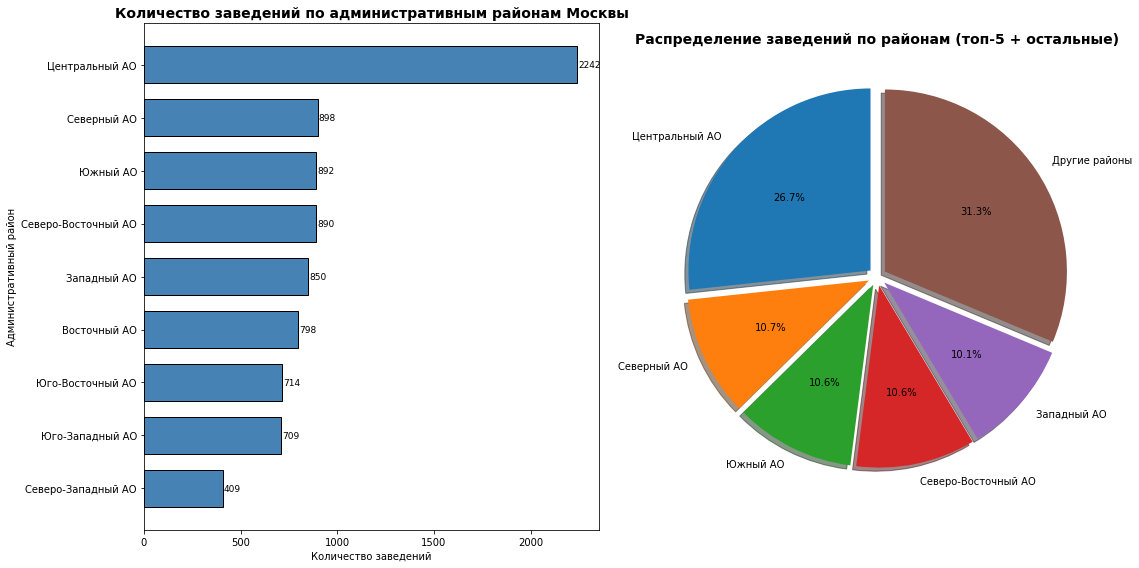

In [47]:
# ВИЗУАЛИЗАЦИЯ ДАННЫХ

# Используем district_counts_short для всех графиков

fig, axes = plt.subplots(1, 2, figsize=(16, 8))

# График 1: Горизонтальная столбчатая диаграмма распределения по районам (с сокращенными названиями)
ax1 = axes[0]
# Сортируем для горизонтальной диаграммы (чтобы самые большие были сверху)
district_counts_sorted = district_counts_short.sort_values(ascending=True)

# Создаем горизонтальную столбчатую диаграмму
bars = ax1.barh(district_counts_sorted.index, district_counts_sorted.values, 
                color='steelblue', edgecolor='black', height=0.7)

ax1.set_title('Количество заведений по административным районам Москвы', 
              fontsize=14, fontweight='bold')
ax1.set_xlabel('Количество заведений')
ax1.set_ylabel('Административный район')

# Добавляем значения на столбцы (справа от каждого столбца)
for i, (index, value) in enumerate(district_counts_sorted.items()):
    ax1.text(value + 5, i, str(value), va='center', fontsize=9)

# График 2: Круговая диаграмма (топ-5 районов + остальные)
ax4 = axes[1]
top_5 = district_counts_short.nlargest(5)
other_districts_sum = district_counts_short.sum() - top_5.sum()
pie_data = pd.concat([top_5, pd.Series({'Другие районы': other_districts_sum})])

# Функция для отображения процентов
def autopct_func(pct):
    return f'{pct:.1f}%' if pct > 3 else ''

wedges, texts, autotexts = ax4.pie(
    pie_data.values, 
    labels=pie_data.index, 
    autopct=autopct_func,
    startangle=90,
    explode=[0.05] * len(pie_data),
    shadow=True
)
ax4.set_title('Распределение заведений по районам (топ-5 + остальные)', 
              fontsize=14, fontweight='bold')

plt.tight_layout()
plt.show()

In [48]:
# Подсчет категорий в ЦАО
cao_data = data[data['district'].str.contains('Центральный', na=False)]
cao_categories = cao_data['category'].value_counts()
category_counts = data['category'].value_counts()

In [49]:
# Распределение категорий в ЦАО
cao_categories.head(10)

ресторан           670
кафе               464
кофейня            428
бар,паб            364
пиццерия           113
быстрое питание     87
столовая            66
булочная            50
Name: category, dtype: int64

In [50]:
pd.DataFrame({
    'ЦАО': cao_categories,
    'Вся Москва': category_counts
}).fillna(0).astype(int)

,ЦАО,Вся Москва
"бар,паб",364,764
булочная,50,256
быстрое питание,87,603
кафе,464,2376
кофейня,428,1413
пиццерия,113,633
ресторан,670,2042
столовая,66,315


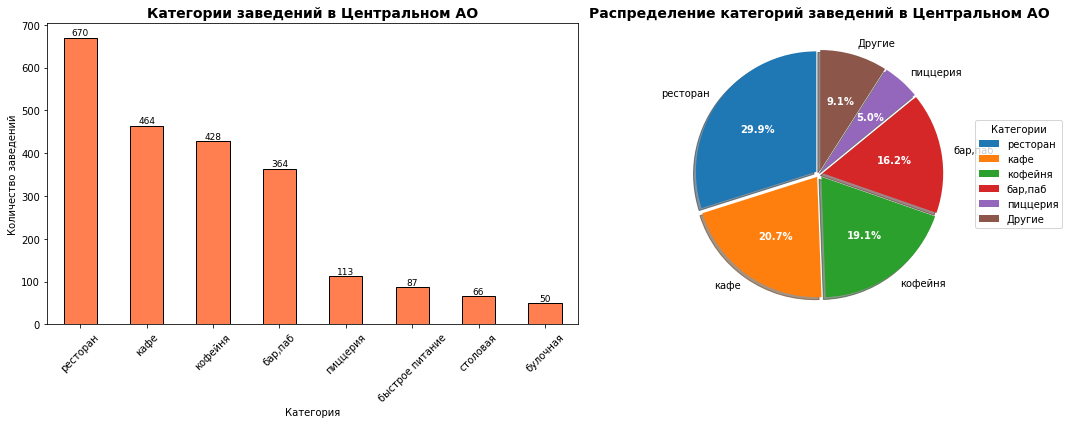

In [51]:
# ВИЗУАЛИЗАЦИЯ РАСПРЕДЕЛЕНИЯ ПО КАТЕГОРИЯМ

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# График 1: Распределение категорий в ЦАО (столбчатая диаграмма)
ax1 = axes[0]
cao_categories.sort_values(ascending=False).head(15).plot(
    kind='bar', 
    ax=ax1, 
    color='coral', 
    edgecolor='black'
)
ax1.set_title('Категории заведений в Центральном АО', fontsize=14, fontweight='bold')
ax1.set_xlabel('Категория')
ax1.set_ylabel('Количество заведений')
ax1.tick_params(axis='x', rotation=45)

# Добавляем значения на столбцы
for i, v in enumerate(cao_categories.sort_values(ascending=False).head(15).values):
    ax1.text(i, v + 0.5, str(v), ha='center', va='bottom', fontsize=9)

# График 2: Круговая диаграмма распределения категорий в ЦАО
ax2 = axes[1]

# Берем топ-5 категорий для круговой диаграммы, остальные объединяем
top_5_cao = cao_categories.nlargest(5)
other_cao = cao_categories.sum() - top_5_cao.sum()
if other_cao > 0:
    pie_cao_data = pd.concat([top_5_cao, pd.Series({'Другие': other_cao})])
else:
    pie_cao_data = top__cao

# Функция для отображения процентов
def autopct_func(pct):
    return f'{pct:.1f}%' if pct > 2 else ''

# Создаем круговую диаграмму
wedges, texts, autotexts = ax2.pie(
    pie_cao_data.values, 
    labels=pie_cao_data.index, 
    autopct=autopct_func,
    startangle=90,
    explode=[0.03] * len(pie_cao_data),  # Небольшое выделение всех секторов
    shadow=True,
    textprops={'fontsize': 10}
)

# Настройка внешнего вида процентов
for autotext in autotexts:
    autotext.set_color('white')
    autotext.set_fontsize(10)
    autotext.set_fontweight('bold')

ax2.set_title('Распределение категорий заведений в Центральном АО', 
              fontsize=14, fontweight='bold')

# Добавляем легенду для наглядности
ax2.legend(wedges, pie_cao_data.index, title="Категории", 
          loc="center left", bbox_to_anchor=(1, 0, 0.5, 1))

plt.tight_layout()
plt.show()

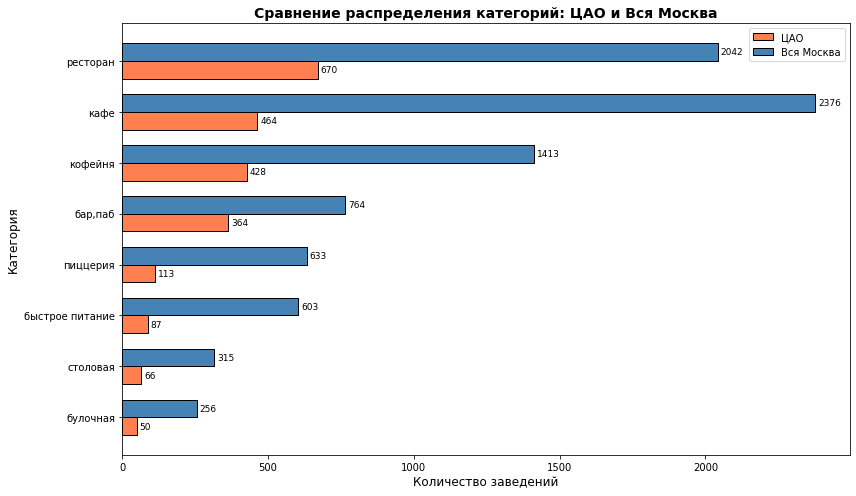

In [52]:
# СРАВНЕНИЕ РАСПРЕДЕЛЕНИЯ КАТЕГОРИЙ: ЦАО vs ВСЯ МОСКВА (ГОРИЗОНТАЛЬНЫЙ ГРАФИК)

# Получаем топ-категории для всей Москвы
top_categories_total = category_counts.nlargest(10)

# Создаем DataFrame для сравнения
comparison_df = pd.DataFrame({
    'ЦАО': cao_categories,
    'Вся Москва': category_counts
}).fillna(0)

# Берем только топ-10 категорий по сумме
top_categories = comparison_df.nlargest(10, 'ЦАО').sort_values('ЦАО', ascending=True)

# Визуализация
fig, ax = plt.subplots(figsize=(12, 7))

y = np.arange(len(top_categories.index))
height = 0.35

# Создаем горизонтальные столбцы
bars1 = ax.barh(y - height/2, top_categories['ЦАО'], height, label='ЦАО', color='coral', edgecolor='black')
bars2 = ax.barh(y + height/2, top_categories['Вся Москва'], height, label='Вся Москва', color='steelblue', edgecolor='black')

ax.set_xlabel('Количество заведений', fontsize=12)
ax.set_ylabel('Категория', fontsize=12)
ax.set_title('Сравнение распределения категорий: ЦАО и Вся Москва', fontsize=14, fontweight='bold')
ax.set_yticks(y)
ax.set_yticklabels(top_categories.index)
ax.legend()

# Добавляем значения на столбцы (справа от каждого столбца)
for bars in [bars1, bars2]:
    for bar in bars:
        width = bar.get_width()
        if width > 0:
            ax.text(width + 10, bar.get_y() + bar.get_height()/2,
                   f'{int(width)}', ha='left', va='center', fontsize=9)

plt.tight_layout()
plt.show()

In [53]:
# Расчет долей для наглядного сравнения
shares = pd.DataFrame({
    'Доля в ЦАО, %': (cao_categories / len(cao_data) * 100).round(1),
    'Доля в Москве, %': (category_counts / len(data) * 100).round(1)
})
shares['Разница, п.п.'] = (shares['Доля в ЦАО, %'] - shares['Доля в Москве, %']).round(1)
shares.sort_values('Доля в ЦАО, %', ascending=False).head(8)

,"Доля в ЦАО, %","Доля в Москве, %","Разница, п.п."
ресторан,29.9,24.3,5.6
кафе,20.7,28.3,-7.6
кофейня,19.1,16.8,2.3
"бар,паб",16.2,9.1,7.1
пиццерия,5.0,7.5,-2.5
быстрое питание,3.9,7.2,-3.3
столовая,2.9,3.7,-0.8
булочная,2.2,3.0,-0.8


**Промежуточные выводы:**

- В датасете представлено 9 административных районов Москвы.
- Из 8402 заведений, представленных в датасете, 2242 относятся к Центральному административному округу (ЦАО) — это 26,7%.
- На долю САО, ЮАО, СВАО и ЗАО приходится от 10,1% до 10,7% заведений. На остальные округа — 31,3%.
- В ЦАО 29,9% заведений приходится на рестораны, 20,7% — на кафе, 19,1% — на кофейни, 16,2% — на бары и пабы. Доля остальных заведений — 14,0%.
- Для ЦАО характерно большее относительное количество ресторанов (+5,6 п.п.), баров и пабов (+7,1 п.п.) и кофеен (+2,3 п.п.). Меньше — кафе (−7,6 п.п.), заведений быстрого питания (−3,3 п.п.) и пиццерий (−2,5 п.п.). Доли столовых и булочных в ЦАО и по Москве практически совпадают (разница −0,8 п.п.).

---

### Задача 3

***Изучите соотношение сетевых и несетевых заведений в целом по всем данным и в разрезе категорий заведения. Каких заведений больше — сетевых или несетевых? Какие категории заведений чаще являются сетевыми? Исследуйте данные, ответьте на вопросы и постройте необходимые визуализации.***

In [54]:
# ОБЩЕЕ СООТНОШЕНИЕ СЕТЕВЫХ И НЕСЕТЕВЫХ ЗАВЕДЕНИЙ

chain_counts = data['chain'].value_counts().sort_index()
chain_counts.index = ['Несетевые (0)', 'Сетевые (1)']
pd.DataFrame({
    'count': chain_counts,
    'share_%': (chain_counts / len(data) * 100).round(1)
})

,count,share_%
Несетевые (0),5199,61.9
Сетевые (1),3203,38.1


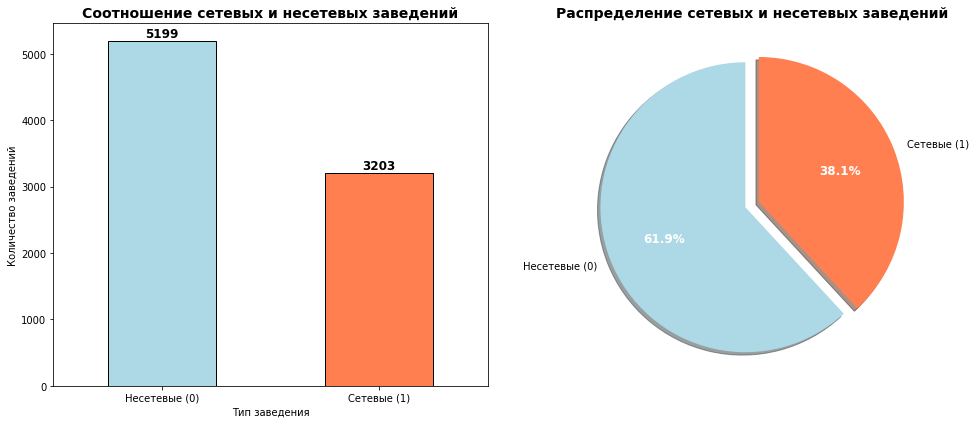

In [55]:
# ВИЗУАЛИЗАЦИЯ ОБЩЕГО СООТНОШЕНИЯ

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# График 1: Столбчатая диаграмма
ax1 = axes[0]
chain_counts.plot(kind='bar', ax=ax1, color=['lightblue', 'coral'], edgecolor='black')
ax1.set_title('Соотношение сетевых и несетевых заведений', fontsize=14, fontweight='bold')
ax1.set_xlabel('Тип заведения')
ax1.set_ylabel('Количество заведений')
ax1.tick_params(axis='x', rotation=0)

# Добавляем значения на столбцы
for i, v in enumerate(chain_counts.values):
    ax1.text(i, v + 10, str(v), ha='center', va='bottom', fontsize=12, fontweight='bold')

# График 2: Круговая диаграмма
ax2 = axes[1]
wedges, texts, autotexts = ax2.pie(
    chain_counts.values, 
    labels=chain_counts.index, 
    autopct='%1.1f%%',
    startangle=90,
    colors=['lightblue', 'coral'],
    explode=(0.05, 0.05),
    shadow=True
)
ax2.set_title('Распределение сетевых и несетевых заведений', fontsize=14, fontweight='bold')

# Настройка внешнего вида процентов
for autotext in autotexts:
    autotext.set_color('white')
    autotext.set_fontsize(12)
    autotext.set_fontweight('bold')

plt.tight_layout()
plt.show()

In [56]:
# АНАЛИЗ ПО КАТЕГОРИЯМ ЗАВЕДЕНИЙ

category_chain = pd.crosstab(data['category'], data['chain'])
category_chain.columns = ['Несетевые', 'Сетевые']
category_chain['Всего'] = category_chain.sum(axis=1)
category_chain['Доля_сетевых_%'] = (category_chain['Сетевые'] / category_chain['Всего'] * 100).round(1)
category_chain_sorted = category_chain.sort_values('Доля_сетевых_%', ascending=False)
category_chain_sorted

,Несетевые,Сетевые,Всего,Доля_сетевых_%
category,,,,
булочная,99,157,256,61.3
пиццерия,303,330,633,52.1
кофейня,693,720,1413,51.0
быстрое питание,371,232,603,38.5
ресторан,1313,729,2042,35.7
кафе,1597,779,2376,32.8
столовая,227,88,315,27.9
"бар,паб",596,168,764,22.0


In [57]:
# КАТЕГОРИИ, КОТОРЫЕ ЧАЩЕ ВСЕГО ЯВЛЯЮТСЯ СЕТЕВЫМИ

category_chain_sorted[['Доля_сетевых_%', 'Всего']].head(5)


,Доля_сетевых_%,Всего
category,,
булочная,61.3,256
пиццерия,52.1,633
кофейня,51.0,1413
быстрое питание,38.5,603
ресторан,35.7,2042


In [58]:
# КАТЕГОРИИ С МАКСИМАЛЬНЫМ КОЛИЧЕСТВОМ СЕТЕВЫХ ЗАВЕДЕНИЙ

category_chain_sorted.sort_values('Сетевые', ascending=False)[['Сетевые', 'Всего', 'Доля_сетевых_%']].head(5)

,Сетевые,Всего,Доля_сетевых_%
category,,,
кафе,779,2376,32.8
ресторан,729,2042,35.7
кофейня,720,1413,51.0
пиццерия,330,633,52.1
быстрое питание,232,603,38.5


In [59]:
category_by_chain_count = category_chain_sorted.sort_values('Сетевые', ascending=False)
category_by_chain_count[['Сетевые', 'Всего', 'Доля_сетевых_%']].head(5)

,Сетевые,Всего,Доля_сетевых_%
category,,,
кафе,779,2376,32.8
ресторан,729,2042,35.7
кофейня,720,1413,51.0
пиццерия,330,633,52.1
быстрое питание,232,603,38.5


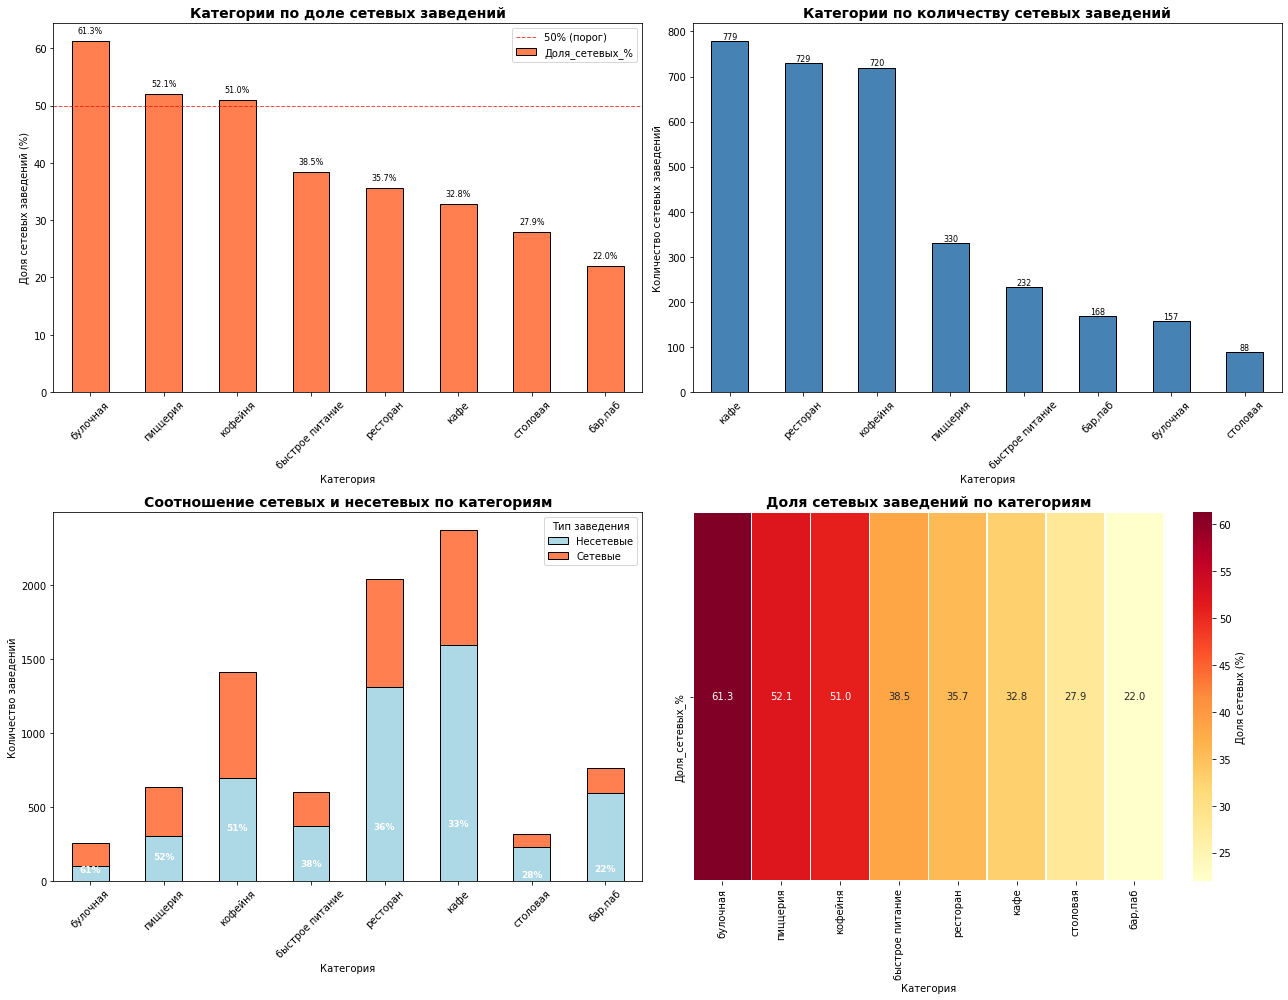

In [60]:
# ВИЗУАЛИЗАЦИЯ РАСПРЕДЕЛЕНИЯ ПО КАТЕГОРИЯМ

fig, axes = plt.subplots(2, 2, figsize=(18, 14))

# График 1: Категории по доле сетевых заведений
ax1 = axes[0, 0]
top_chain_pct = category_chain_sorted.head(8)
top_chain_pct['Доля_сетевых_%'].plot(
    kind='bar', 
    ax=ax1, 
    color='coral', 
    edgecolor='black'
)
ax1.set_title('Категории по доле сетевых заведений', fontsize=14, fontweight='bold')
ax1.set_xlabel('Категория')
ax1.set_ylabel('Доля сетевых заведений (%)')
ax1.tick_params(axis='x', rotation=45)  # Удален параметр ha='right'
ax1.axhline(y=50, color='red', linestyle='--', linewidth=1, alpha=0.7, label='50% (порог)')
ax1.legend()

# Добавляем значения
for i, v in enumerate(top_chain_pct['Доля_сетевых_%'].values):
    ax1.text(i, v + 1, f'{v}%', ha='center', va='bottom', fontsize=8)

# График 2: Категории по количеству сетевых заведений
ax2 = axes[0, 1]
top_chain_count = category_by_chain_count.head(15)
top_chain_count['Сетевые'].plot(
    kind='bar', 
    ax=ax2, 
    color='steelblue', 
    edgecolor='black'
)
ax2.set_title('Категории по количеству сетевых заведений', fontsize=14, fontweight='bold')
ax2.set_xlabel('Категория')
ax2.set_ylabel('Количество сетевых заведений')
ax2.tick_params(axis='x', rotation=45)  # Удален параметр ha='right'

# Добавляем значения
for i, v in enumerate(top_chain_count['Сетевые'].values):
    ax2.text(i, v + 0.5, str(v), ha='center', va='bottom', fontsize=8)

# График 3: Соотношение сетевых и несетевых по категориям
ax3 = axes[1, 0]
top_categories = category_chain_sorted.head(8).index
chain_ratio_data = category_chain.loc[top_categories]

# Строим stacked bar chart
chain_ratio_data[['Несетевые', 'Сетевые']].plot(
    kind='bar', 
    ax=ax3, 
    stacked=True,
    color=['lightblue', 'coral'],
    edgecolor='black'
)
ax3.set_title('Соотношение сетевых и несетевых по категориям', fontsize=14, fontweight='bold')
ax3.set_xlabel('Категория')
ax3.set_ylabel('Количество заведений')
ax3.tick_params(axis='x', rotation=45)  # Удален параметр ha='right'
ax3.legend(title='Тип заведения')

# Добавляем проценты на столбцы
for i, category in enumerate(top_categories):
    total = chain_ratio_data.loc[category, 'Всего']
    chain_count = chain_ratio_data.loc[category, 'Сетевые']
    if chain_count > 0:
        chain_pct = (chain_count / total * 100)
        ax3.text(i, chain_count/2, f'{chain_pct:.0f}%', 
                ha='center', va='center', color='white', fontweight='bold', fontsize=9)

# График 4: Распределение категорий по степени сетевости (heatmap)
ax4 = axes[1, 1]

# Создаем данные для heatmap - доля сетевых по категориям
chain_pivot = category_chain_sorted[['Доля_сетевых_%']].head(8)

# Создаем heatmap
sns.heatmap(
    chain_pivot.T, 
    annot=True, 
    fmt='.1f', 
    cmap='YlOrRd', 
    linewidths=0.5,
    cbar_kws={'label': 'Доля сетевых (%)'},
    ax=ax4
)
ax4.set_title('Доля сетевых заведений по категориям', fontsize=14, fontweight='bold')
ax4.set_xlabel('Категория')
ax4.set_ylabel('')

plt.tight_layout()
plt.show()

**Промежуточные выводы:**

- Сетевые заведения занимают более 1/3 рынка, в которых в относительном пересчете преобладают булочные, пиццерии и кофейни

- В абсолютном значении первенство за кафе, ресторанами и кофейнями (примерно в равном соотношении)

- В Западном АО незначительно преобладают сетевые заведения

- Сегменты быстрого питания (кофейни, пиццерии, булочные) демонстрируют высокий уровень консолидации — более 50% заведений являются сетевыми. Это говорит о том, что рынок уже поделён крупными игроками, а конкуренция строится на узнаваемости бренда и стандартизации сервиса.

- Для входа в эти сегменты новым игрокам потребуется либо значительный бюджет на маркетинг, либо уникальная концепция, отличающаяся от существующих сетей. Инвесторам стоит обратить внимание на франшизы в этих категориях — они уже доказали свою жизнеспособность.

---

### Задача 4

***Исследуйте количество посадочных мест в заведениях. Встречаются ли в данных аномальные значения или выбросы? Если да, то с чем они могут быть связаны? Приведите для каждой категории заведений наиболее типичное для него количество посадочных мест. Результат сопроводите подходящими визуализациями.***


In [61]:
# ОБЩИЙ АНАЛИЗ КОЛИЧЕСТВА ПОСАДОЧНЫХ МЕСТ

data['seats'].describe()

count    4792.000000
mean      108.361436
std       122.841130
min         0.000000
25%        40.000000
50%        75.000000
75%       140.000000
max      1288.000000
Name: seats, dtype: float64

In [62]:
seats_stats = data['seats'].describe()

Q1, Q3 = data['seats'].quantile([0.25, 0.75])
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

seats_stats

count    4792.000000
mean      108.361436
std       122.841130
min         0.000000
25%        40.000000
50%        75.000000
75%       140.000000
max      1288.000000
Name: seats, dtype: float64

In [63]:
print(f'IQR = {IQR:.1f}, границы: [{lower_bound:.1f}; {upper_bound:.1f}]')

IQR = 100.0, границы: [-110.0; 290.0]


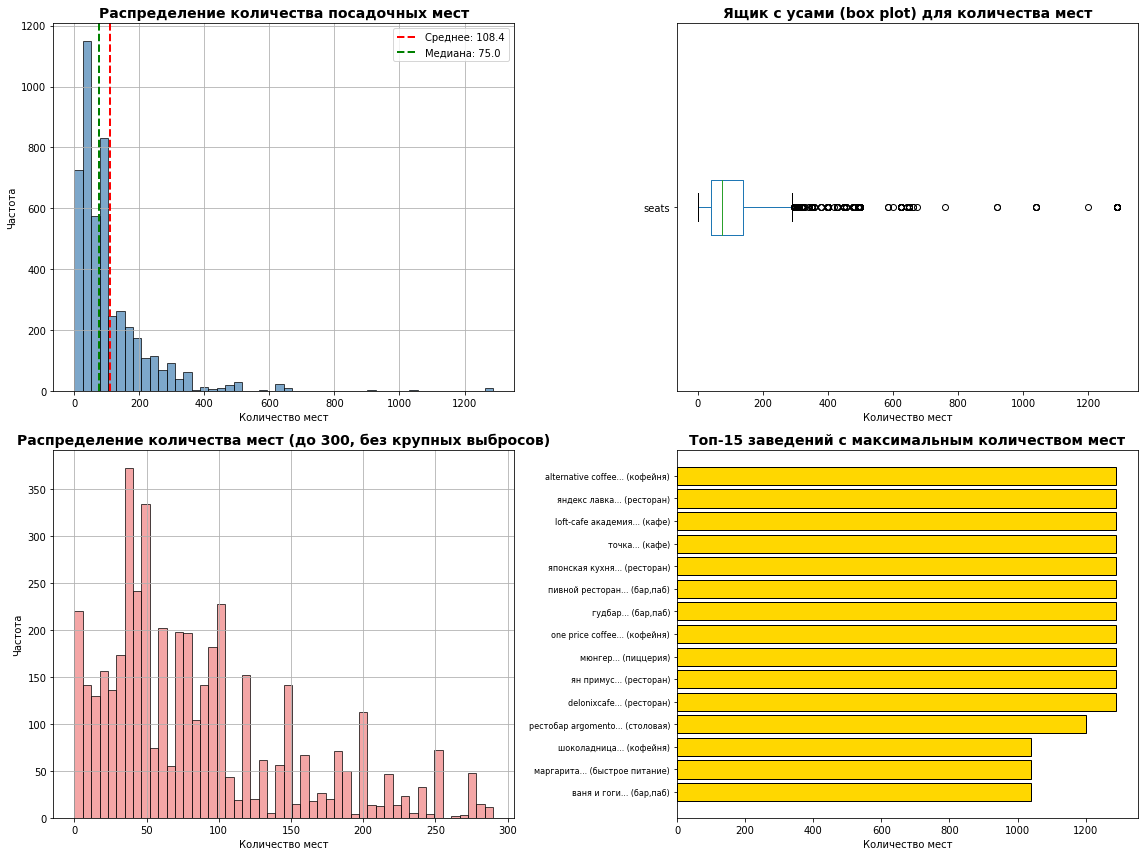

In [64]:
# ВИЗУАЛИЗАЦИЯ РАСПРЕДЕЛЕНИЯ

fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# График 1: Гистограмма распределения
ax1 = axes[0, 0]
data['seats'].dropna().hist(bins=50, ax=ax1, color='steelblue', edgecolor='black', alpha=0.7)
ax1.set_title('Распределение количества посадочных мест', fontsize=14, fontweight='bold')
ax1.set_xlabel('Количество мест')
ax1.set_ylabel('Частота')
ax1.axvline(seats_stats['mean'], color='red', linestyle='--', linewidth=2, label=f"Среднее: {seats_stats['mean']:.1f}")
ax1.axvline(seats_stats['50%'], color='green', linestyle='--', linewidth=2, label=f"Медиана: {seats_stats['50%']:.1f}")
ax1.legend()

# График 2: Ящик с усами (box plot)
ax2 = axes[0, 1]
data['seats'].dropna().plot(kind='box', ax=ax2, vert=False)
ax2.set_title('Ящик с усами (box plot) для количества мест', fontsize=14, fontweight='bold')
ax2.set_xlabel('Количество мест')

# График 3: Распределение с акцентом на выбросы
ax3 = axes[1, 0]
# Ограничиваем ось X для лучшей визуализации основной массы
data['seats'].dropna().hist(bins=50, ax=ax3, color='lightcoral', edgecolor='black', alpha=0.7, range=(0, min(upper_bound, 300)))
ax3.set_title('Распределение количества мест (до 300, без крупных выбросов)', fontsize=14, fontweight='bold')
ax3.set_xlabel('Количество мест')
ax3.set_ylabel('Частота')

# График 4: Топ-15 заведений с максимальным количеством мест
ax4 = axes[1, 1]
top_15_seats = data.nlargest(15, 'seats')[['name', 'seats', 'category']].copy()
top_15_seats = top_15_seats.sort_values('seats', ascending=True)  # Для горизонтального отображения
ax4.barh(range(len(top_15_seats)), top_15_seats['seats'].values, color='gold', edgecolor='black')
ax4.set_yticks(range(len(top_15_seats)))
ax4.set_yticklabels([f"{row['name'][:30]}... ({row['category']})" for _, row in top_15_seats.iterrows()], fontsize=8)
ax4.set_title('Топ-15 заведений с максимальным количеством мест', fontsize=14, fontweight='bold')
ax4.set_xlabel('Количество мест')

plt.tight_layout()
plt.show()

In [65]:
# АНАЛИЗ АНОМАЛЬНЫХ ЗНАЧЕНИЙ

large_outliers = data[data['seats'] > 600].sort_values('seats', ascending=False)
large_outliers[['name', 'seats', 'category']].head(20)


,name,seats,category
6574,мюнгер,1288,пиццерия
6838,alternative coffee,1288,кофейня
6808,яндекс лавка,1288,ресторан
6807,loft-cafe академия,1288,кафе
6771,точка,1288,кафе
6690,японская кухня,1288,ресторан
6684,пивной ресторан,1288,"бар,паб"
6658,гудбар,1288,"бар,паб"
6641,one price coffee,1288,кофейня
6524,ян примус,1288,ресторан


In [66]:
# Анализ категорий с выбросами
large_outliers['category'].value_counts()

кофейня            12
кафе               12
ресторан           12
бар,паб             9
пиццерия            4
столовая            2
быстрое питание     1
булочная            1
Name: category, dtype: int64

In [67]:
data[data['seats'] < 5].shape[0]

193

In [68]:
# ИЗУЧЕНИЕ АНОМАЛЬНЫХ ЗНАЧЕНИЙ

# Отфильтруем строки, где значения в столбце seats больше 600
filtered_data = data[data['seats'] > 600]

# Сгруппируем данные по столбцу address и суммируйте значения в столбце seats
grouped_data = filtered_data.groupby('address')['seats'].sum().reset_index()
grouped_data.head(10)

,address,seats
0,"москва, измайловское шоссе, 71, корп. 2б",1320
1,"москва, измайловское шоссе, 71, корп. а",4160
2,"москва, киевская улица, 2",1840
3,"москва, кутузовский проспект, 41, стр. 1",1200
4,"москва, ленинградский проспект, 29, корп. 1",625
5,"москва, ленинградский проспект, 31а, стр. 1",2500
6,"москва, ленинградский проспект, 35, стр. 1",625
7,"москва, ленинградский проспект, 45, корп. 1",625
8,"москва, ленинградский проспект, 48, подъезд 1",625
9,"москва, ленинградский проспект, 60, корп. 1",625


Изучение адресов позволит определить, что является причинами выбросов. Для примера возьмем следующие адреса:

- ***москва, измайловское шоссе, 71, корп. 2б	- 1320*** — Гостиница "Измайлово Бета"
- ***москва, измайловское шоссе, 71, корп. а - 4160*** — Гостиница Измайлово Альфа Москва	
- ***москва, киевская улица, 2 — 1840*** — Торгово-гостиничный комплекс "Киевский"
- ***москва, кутузовский проспект, 41, стр. 1 — 1200*** — Московский научно-практический центр дерматовенерологии и косметологии Департамента здравоохранения города Москвы
- ***москва, ленинградский проспект, 29, корп. 1	— 625*** — Жилой комплекс "Екатерининский"

*Поверхностный анализ и сопоставление адресов с Яндекс.Картами показывают, что данные с указанными выбросами имеют искаженные значения. Количество посадочных мест может указываться, как общее для фудкортов торговых центров, номеров в гостиницах или количества квартир в жилых комплексах.*

*Что касается выбросов для низких значений, то скорее всего речь идет о фастфудах, в которых нет посадочных мест (еда на вынос), пунктах, которые работают только в качестве доставок и т.д.

In [69]:
# ДОПОЛНИТЕЛЬНОЕ ИССЛЕДОВАНИЕ ЗАВЕДЕНИЙ С БОЛЬШИМ КОЛИЧЕСТВОМ МЕСТ

large_seats = data[data['seats'] > 600].copy()
large_seats[['name', 'address', 'seats']].sort_values('seats', ascending=False)

,name,address,seats
6574,мюнгер,"москва, проспект вернадского, 97, корп. 1",1288
6838,alternative coffee,"москва, проспект вернадского, 41, стр. 1",1288
6808,яндекс лавка,"москва, проспект вернадского, 51, стр. 1",1288
6807,loft-cafe академия,"москва, проспект вернадского, 84, стр. 1",1288
6771,точка,"москва, проспект вернадского, 84, стр. 1",1288
6690,японская кухня,"москва, проспект вернадского, 121, корп. 1",1288
6684,пивной ресторан,"москва, проспект вернадского, 121, корп. 1",1288
6658,гудбар,"москва, проспект вернадского, 97, корп. 1",1288
6641,one price coffee,"москва, проспект вернадского, 84, стр. 1",1288
6524,ян примус,"москва, проспект вернадского, 121, корп. 1",1288


In [70]:
address_group = large_seats.groupby('address').agg(
    Количество_заведений=('seats', 'count'),
    Среднее_мест=('seats', 'mean'),
    Мин_мест=('seats', 'min'),
    Макс_мест=('seats', 'max'),
    Сумма_мест=('seats', 'sum')
)

address_group['Среднее_мест'] = address_group['Среднее_мест'].astype(float).round(0).astype(int)
address_group = address_group.sort_values('Количество_заведений', ascending=False)
address_group

,Количество_заведений,Среднее_мест,Мин_мест,Макс_мест,Сумма_мест
address,,,,,
"москва, ленинградский проспект, 31а, стр. 1",4,625,625,625,2500
"москва, измайловское шоссе, 71, корп. а",4,1040,1040,1040,4160
"москва, ленинградский проспект, 72, корп. 1",3,625,625,625,1875
"москва, проспект вернадского, 84, стр. 1",3,1288,1288,1288,3864
"москва, проспект вернадского, 121, корп. 1",3,1288,1288,1288,3864
"москва, измайловское шоссе, 71, корп. 2б",2,660,660,660,1320
"москва, улица миклухо-маклая, 6",2,644,644,644,1288
"москва, проспект вернадского, 97, корп. 1",2,1288,1288,1288,2576
"москва, мичуринский проспект, 22, корп. 1",2,650,650,650,1300


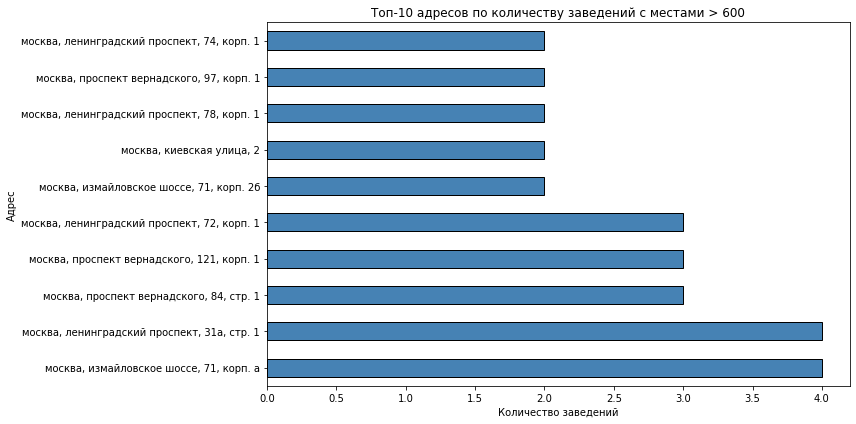

In [71]:
top_addresses = large_seats['address'].value_counts().head(10)
top_addresses.plot(kind='barh', figsize=(12, 6), color='steelblue', edgecolor='black')
plt.title('Топ-10 адресов по количеству заведений с местами > 600')
plt.xlabel('Количество заведений')
plt.ylabel('Адрес')
plt.tight_layout()
plt.show()

In [72]:
# ТИПИЧНОЕ КОЛИЧЕСТВО МЕСТ ПО КАТЕГОРИЯМ

category_seats = data.groupby('category')['seats'].agg([
    'count', 'mean', 'median', 'std', 'min', 'max',
    lambda x: x.quantile(0.25), lambda x: x.quantile(0.75)
])
category_seats.columns = ['Кол-во', 'Среднее', 'Медиана', 'Стд_откл', 'Мин', 'Макс', 'Q1', 'Q3']
category_seats = category_seats.astype(float).round(1).sort_values('Медиана', ascending=False)
category_seats

,Кол-во,Среднее,Медиана,Стд_откл,Мин,Макс,Q1,Q3
category,,,,,,,,
ресторан,1269.0,121.9,86.0,123.8,0.0,1288.0,48.0,150.0
"бар,паб",467.0,124.5,82.0,145.2,0.0,1288.0,48.0,148.5
кофейня,751.0,111.2,80.0,127.8,0.0,1288.0,40.0,144.0
столовая,164.0,99.8,75.5,123.0,0.0,1200.0,40.0,117.0
быстрое питание,349.0,98.9,65.0,106.6,0.0,1040.0,28.0,140.0
кафе,1217.0,97.4,60.0,117.9,0.0,1288.0,35.0,120.0
пиццерия,427.0,94.5,55.0,112.3,0.0,1288.0,30.0,120.0
булочная,148.0,89.4,50.0,97.7,0.0,625.0,25.0,120.0


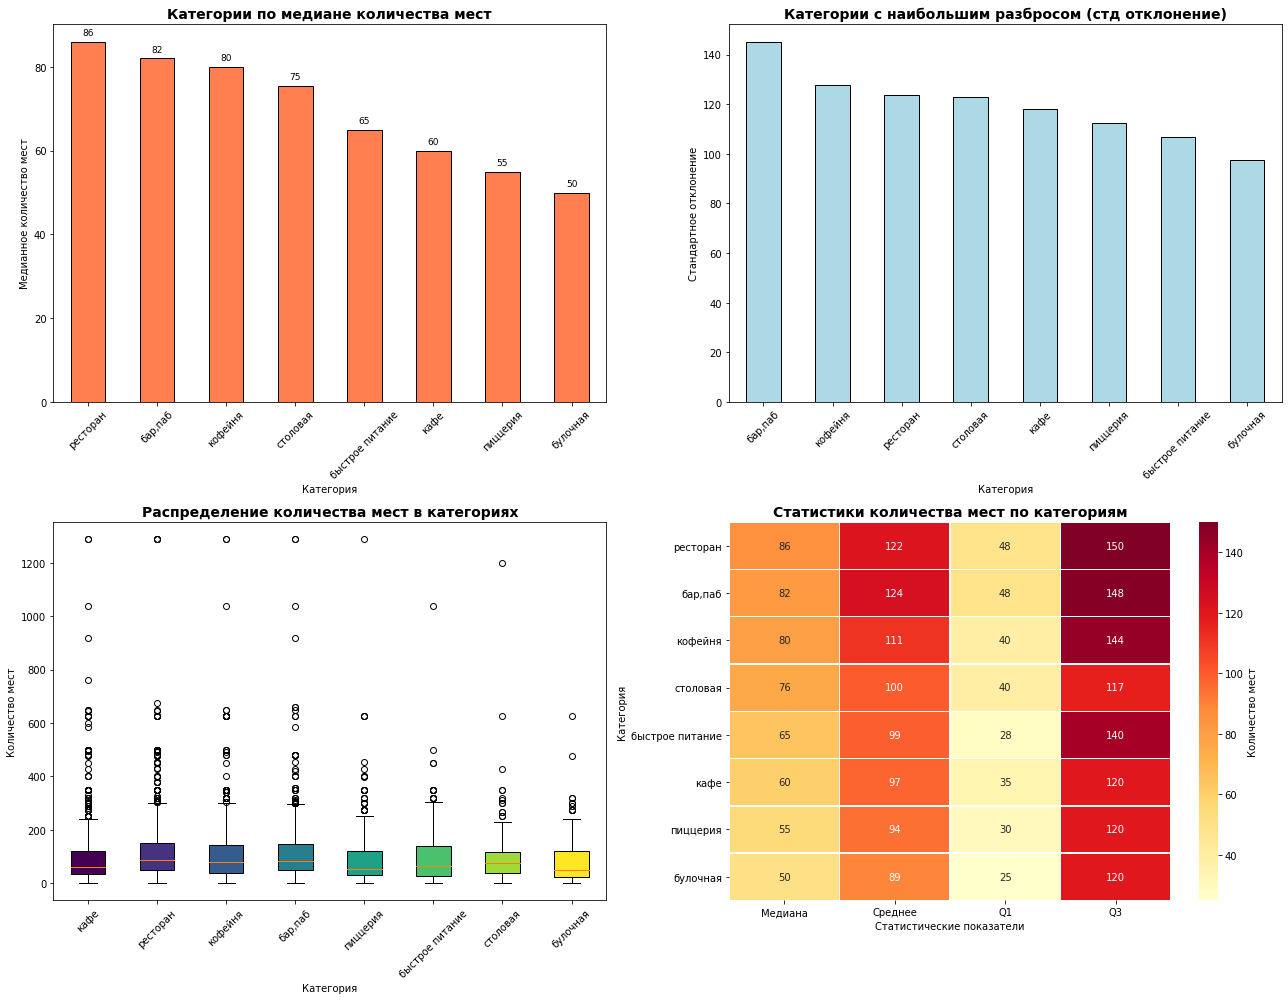

In [73]:
# ВИЗУАЛИЗАЦИЯ ТИПИЧНЫХ ЗНАЧЕНИЙ ПО КАТЕГОРИЯМ

fig, axes = plt.subplots(2, 2, figsize=(18, 14))

# График 1: Категории по медиане количества мест
ax1 = axes[0, 0]
top_by_median = category_seats
top_by_median['Медиана'].plot(kind='bar', ax=ax1, color='coral', edgecolor='black')
ax1.set_title('Категории по медиане количества мест', fontsize=14, fontweight='bold')
ax1.set_xlabel('Категория')
ax1.set_ylabel('Медианное количество мест')
ax1.tick_params(axis='x', rotation=45)

# Добавляем значения
for i, v in enumerate(top_by_median['Медиана'].values):
    ax1.text(i, v + 1, str(int(v)), ha='center', va='bottom', fontsize=9)

# График 2: Категории с наибольшим разбросом (стд отклонение)
ax2 = axes[0, 1]
top_by_std = category_seats.sort_values('Стд_откл', ascending=False).head(15)
top_by_std['Стд_откл'].plot(kind='bar', ax=ax2, color='lightblue', edgecolor='black')
ax2.set_title('Категории с наибольшим разбросом (стд отклонение)', fontsize=14, fontweight='bold')
ax2.set_xlabel('Категория')
ax2.set_ylabel('Стандартное отклонение')
ax2.tick_params(axis='x', rotation=45)

# График 3: Ящики с усами для категорий
ax3 = axes[1, 0]
top_categories = data['category'].value_counts().index
category_seats_box = [data[data['category'] == cat]['seats'].dropna().values for cat in top_categories]

# Создаем box plot
bp = ax3.boxplot(category_seats_box, labels=top_categories, vert=True, patch_artist=True)
ax3.set_title('Распределение количества мест в категориях', fontsize=14, fontweight='bold')
ax3.set_xlabel('Категория')
ax3.set_ylabel('Количество мест')
ax3.tick_params(axis='x', rotation=45)

# Раскрашиваем ящики
for patch, color in zip(bp['boxes'], plt.cm.viridis(np.linspace(0, 1, len(top_categories)))):
    patch.set_facecolor(color)

# График 4: Тепловая карта статистик по категориям
ax4 = axes[1, 1]

heatmap_data = category_seats[['Медиана', 'Среднее', 'Q1', 'Q3']]

sns.heatmap(heatmap_data, annot=True, fmt='.0f', cmap='YlOrRd', 
            linewidths=0.5, cbar_kws={'label': 'Количество мест'}, ax=ax4)
ax4.set_title('Статистики количества мест по категориям', fontsize=14, fontweight='bold')
ax4.set_xlabel('Статистические показатели')
ax4.set_ylabel('Категория')

plt.tight_layout()
plt.show()

In [74]:
# ВЫДЕЛЕНИЕ ТИПИЧНЫХ ЗНАЧЕНИЙ ПО КАТЕГОРИЯМ

print("\n" + "="*70)
print("ТИПИЧНОЕ КОЛИЧЕСТВО МЕСТ ПО КАТЕГОРИЯМ")
print("="*70)

# Создаем DataFrame с типичными значениями
typical_seats = pd.DataFrame({
    'Категория': category_seats.index,
    'Типичное_количество_мест': category_seats['Медиана'].round(0).astype(int),
    'Интервал_Q1_Q3': category_seats.apply(lambda x: f"{int(x['Q1'])}-{int(x['Q3'])}", axis=1),
    'Количество_заведений': category_seats['Кол-во'].astype(int)
}).sort_values('Типичное_количество_мест', ascending=False)
typical_seats


ТИПИЧНОЕ КОЛИЧЕСТВО МЕСТ ПО КАТЕГОРИЯМ


,Категория,Типичное_количество_мест,Интервал_Q1_Q3,Количество_заведений
category,,,,
ресторан,ресторан,86,48-150,1269
"бар,паб","бар,паб",82,48-148,467
кофейня,кофейня,80,40-144,751
столовая,столовая,76,40-117,164
быстрое питание,быстрое питание,65,28-140,349
кафе,кафе,60,35-120,1217
пиццерия,пиццерия,55,30-120,427
булочная,булочная,50,25-120,148


**Вывод:**

1. ОБЩАЯ СТАТИСТИКА:
- Среднее количество мест: 108.4
- Медианное количество мест: 75.0
- Стандартное отклонение: 122.8
- Минимум: 0 мест
- Максимум: 1288 мест

2. ВЫБРОСЫ И АНОМАЛИИ:
- Выявлено 318 заведений-выбросов (6.6% от заведений с данными)
- Верхняя граница нормы (Q3 + 1.5*IQR): 290 мест

*Возможные причины аномалий:*
- Три заведения с 1288 местами — вероятно, данные искажены: количество мест может отражать общее число мест в фуд-корте, гостиничных номеров или квартир в ЖК, а не посадочных мест конкретного заведения.
- 140 заведений с очень малым количеством мест (< 2) — вероятно, это киоски, точки с едой на вынос или заведения, специализирующиеся на доставке.

3. ТИПИЧНОЕ КОЛИЧЕСТВО МЕСТ ПО КАТЕГОРИЯМ:
- Для всех категорий медиана находится в диапазоне 50–86 мест.
- Самые "вместительные" категории: рестораны (86), бары и пабы (82), кофейни (80).
- Самые "компактные" категории: булочные (50), пиццерии (55), кафе (60).

4. РЕКОМЕНДАЦИИ ПО ИСПОЛЬЗОВАНИЮ ДАННЫХ:
- При анализе средних значений нужно учитывать наличие выбросов.
- Для определения типичного размера заведения лучше использовать медиану.
- При необходимости можно исключить выбросы или рассматривать их отдельно.

---

### Задача 5

***Исследуйте рейтинг заведений. Визуализируйте распределение средних рейтингов по категориям заведений. Сильно ли различаются усреднённые рейтинги для разных типов общепита?***

In [75]:
# ОБЩИЙ АНАЛИЗ РЕЙТИНГОВ

rating_stats = data['rating'].describe()
rating_stats

count    8402.000000
mean        4.230016
std         0.470320
min         1.000000
25%         4.100000
50%         4.300000
75%         4.400000
max         5.000000
Name: rating, dtype: float64

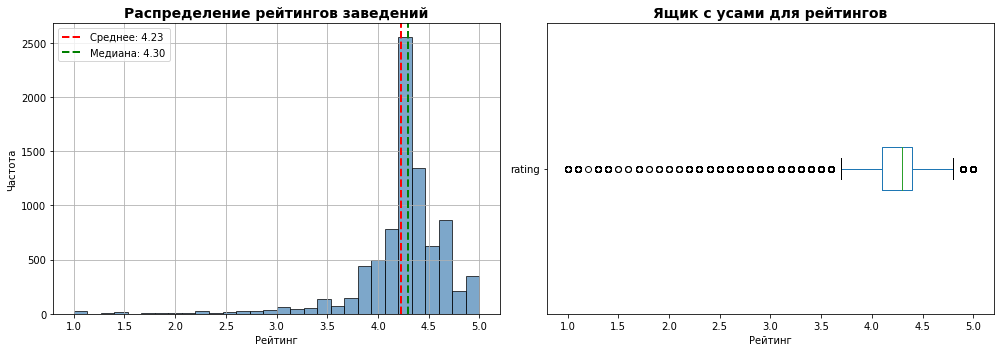

In [76]:
# ВИЗУАЛИЗАЦИЯ ОБЩЕГО РАСПРЕДЕЛЕНИЯ

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# График 1: Гистограмма распределения рейтингов
ax1 = axes[0]
data['rating'].dropna().hist(bins=30, ax=ax1, color='steelblue', edgecolor='black', alpha=0.7)
ax1.set_title('Распределение рейтингов заведений', fontsize=14, fontweight='bold')
ax1.set_xlabel('Рейтинг')
ax1.set_ylabel('Частота')
ax1.axvline(rating_stats['mean'], color='red', linestyle='--', linewidth=2, label=f"Среднее: {rating_stats['mean']:.2f}")
ax1.axvline(rating_stats['50%'], color='green', linestyle='--', linewidth=2, label=f"Медиана: {rating_stats['50%']:.2f}")
ax1.legend()

# График 2: Ящик с усами (box plot)
ax2 = axes[1]
data['rating'].dropna().plot(kind='box', ax=ax2, vert=False)
ax2.set_title('Ящик с усами для рейтингов', fontsize=14, fontweight='bold')
ax2.set_xlabel('Рейтинг')

plt.tight_layout()
plt.show()

In [77]:
# АНАЛИЗ РЕЙТИНГОВ ПО КАТЕГОРИЯМ

category_rating = data.groupby('category')['rating'].agg(
    ['count', 'mean', 'median', 'std', 'min', 'max']
).round(2)

In [78]:
category_rating_sorted = category_rating.sort_values('mean', ascending=False)
category_rating_sorted

,count,mean,median,std,min,max
category,,,,,,
"бар,паб",764,4.39,4.4,0.38,1.1,5.0
пиццерия,633,4.30,4.3,0.34,1.0,5.0
ресторан,2042,4.29,4.3,0.41,1.0,5.0
кофейня,1413,4.28,4.3,0.37,1.4,5.0
булочная,256,4.27,4.3,0.39,1.3,5.0
столовая,315,4.21,4.3,0.45,1.0,5.0
кафе,2376,4.12,4.2,0.57,1.0,5.0
быстрое питание,603,4.05,4.2,0.56,1.1,5.0


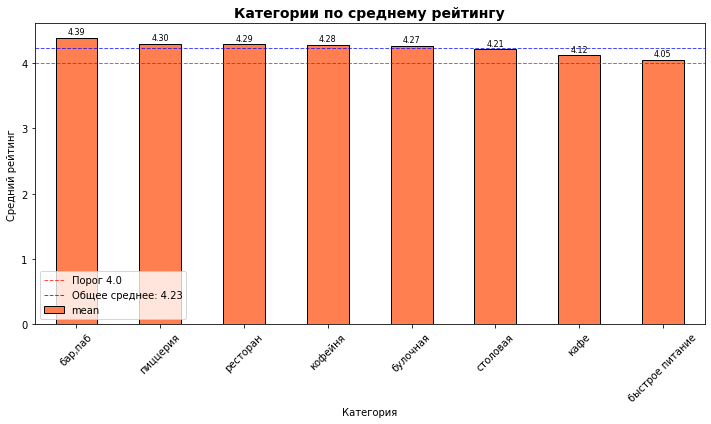

In [79]:
# ВИЗУАЛИЗАЦИЯ РАСПРЕДЕЛЕНИЯ РЕЙТИНГОВ ПО КАТЕГОРИЯМ

fig, ax = plt.subplots(figsize=(10, 6))

top_rating = category_rating_sorted.head(8)
top_rating['mean'].plot(kind='bar', ax=ax, color='coral', edgecolor='black')
ax.set_title('Категории по среднему рейтингу', fontsize=14, fontweight='bold')
ax.set_xlabel('Категория')
ax.set_ylabel('Средний рейтинг')
ax.tick_params(axis='x', rotation=45)
ax.axhline(y=4.0, color='red', linestyle='--', linewidth=1, alpha=0.7, label='Порог 4.0')
ax.axhline(y=rating_stats['mean'], color='blue', linestyle='--', linewidth=1, alpha=0.7,
           label=f'Общее среднее: {rating_stats["mean"]:.2f}')
ax.legend()

for i, v in enumerate(top_rating['mean'].values):
    ax.text(i, v + 0.02, f'{v:.2f}', ha='center', va='bottom', fontsize=8)

plt.tight_layout()
plt.show()

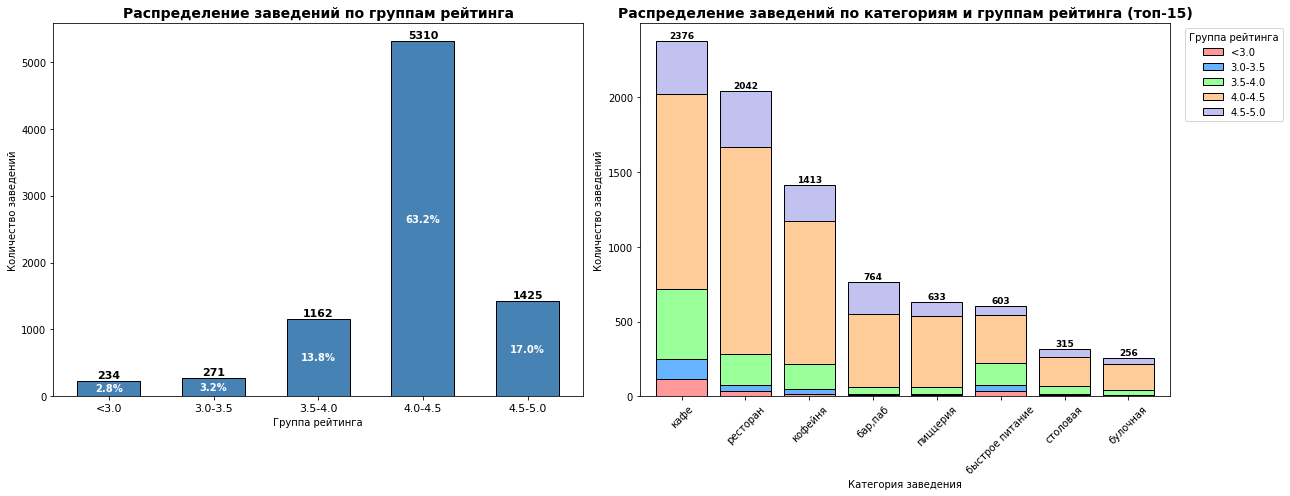

In [80]:
# ДОПОЛНИТЕЛЬНАЯ ВИЗУАЛИЗАЦИЯ: СРАВНЕНИЕ КАТЕГОРИЙ

# Создаем категории рейтингов
rating_bins = [0, 3.0, 3.5, 4.0, 4.5, 5.0]
rating_labels = ['<3.0', '3.0-3.5', '3.5-4.0', '4.0-4.5', '4.5-5.0']
data['rating_group'] = pd.cut(data['rating'], bins=rating_bins, labels=rating_labels)

# Создаем фигуру с двумя графиками
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

# ГРАФИК 1: Количество заведений в группах рейтинга (общее распределение)
ax1 = axes[0]

# Считаем количество заведений в каждой группе рейтингов
rating_group_counts = data['rating_group'].value_counts().sort_index()

# Строим столбчатую диаграмму
bars = ax1.bar(
    range(len(rating_group_counts)), 
    rating_group_counts.values, 
    color='steelblue', 
    edgecolor='black',
    width=0.6
)
ax1.set_xticks(range(len(rating_group_counts)))
ax1.set_xticklabels(rating_group_counts.index, fontsize=11)
ax1.set_title('Распределение заведений по группам рейтинга', fontsize=14, fontweight='bold')
ax1.set_xlabel('Группа рейтинга')
ax1.set_ylabel('Количество заведений')
ax1.tick_params(axis='x', rotation=0)

# Добавляем значения на столбцы
for i, (bar, v) in enumerate(zip(bars, rating_group_counts.values)):
    ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 10, 
             str(v), ha='center', va='bottom', fontsize=11, fontweight='bold')

# Добавляем проценты
total = rating_group_counts.sum()
for i, (bar, v) in enumerate(zip(bars, rating_group_counts.values)):
    percentage = (v / total * 100)
    ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height()/2, 
             f'{percentage:.1f}%', ha='center', va='center', color='white', fontsize=10, fontweight='bold')

# ГРАФИК 2: Количество заведений по категориям с разбивкой по группам рейтинга
ax2 = axes[1]

# Получаем категории по общему количеству заведений
top_categories = data['category'].value_counts().head(8).index

# Фильтруем данные только для топ-15 категорий
top_categories_data = data[data['category'].isin(top_categories)]

# Создаем сводную таблицу: категории vs группы рейтинга
pivot_table = pd.crosstab(
    top_categories_data['category'], 
    top_categories_data['rating_group'],
    margins=False
)

# Сортируем категории по общему количеству заведений
category_order = top_categories_data['category'].value_counts().index
pivot_table = pivot_table.loc[category_order]

# Строим stacked bar chart
pivot_table.plot(
    kind='bar', 
    ax=ax2, 
    stacked=True,
    color=['#ff9999', '#66b3ff', '#99ff99', '#ffcc99', '#c2c2f0'],
    edgecolor='black',
    width=0.8
)
ax2.set_title('Распределение заведений по категориям и группам рейтинга (топ-15)', 
              fontsize=14, fontweight='bold')
ax2.set_xlabel('Категория заведения')
ax2.set_ylabel('Количество заведений')
ax2.tick_params(axis='x', rotation=45)
ax2.legend(title='Группа рейтинга', bbox_to_anchor=(1.02, 1), loc='upper left')

# Добавляем общее количество над столбцами
for i, category in enumerate(pivot_table.index):
    total = pivot_table.loc[category].sum()
    ax2.text(i, total + 5, str(total), ha='center', va='bottom', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()

In [81]:
# Дополнительная статистика по категориям и рейтингам
category_rating['mean'].describe()

count    8.000000
mean     4.238750
std      0.108554
min      4.050000
25%      4.187500
50%      4.275000
75%      4.292500
max      4.390000
Name: mean, dtype: float64

In [82]:
category_rating[['mean', 'count']].head(3)

,mean,count
category,,
"бар,паб",4.39,764
булочная,4.27,256
быстрое питание,4.05,603


In [83]:
category_rating[['mean', 'count']].tail(3)

,mean,count
category,,
пиццерия,4.30,633
ресторан,4.29,2042
столовая,4.21,315


In [84]:
# АНАЛИЗ РАЗЛИЧИЙ МЕЖДУ КАТЕГОРИЯМИ

print("\n" + "="*70)
print("АНАЛИЗ РАЗЛИЧИЙ РЕЙТИНГОВ МЕЖДУ КАТЕГОРИЯМИ")
print("="*70)

# Рассчитываем статистику по категориям
min_mean = category_rating['mean'].min()
max_mean = category_rating['mean'].max()
range_mean = max_mean - min_mean
std_mean = category_rating['mean'].std()

print(f"\nСтатистика различий средних рейтингов по категориям:")
print(f"• Минимальный средний рейтинг среди категорий: {min_mean:.2f}")
print(f"• Максимальный средний рейтинг среди категорий: {max_mean:.2f}")
print(f"• Размах (разница между макс и мин): {range_mean:.2f}")
print(f"• Стандартное отклонение средних: {std_mean:.2f}")

# Находим категории с экстремальными рейтингами
print(f"\nКатегории с самыми высокими средними рейтингами:")
for i, (cat, row) in enumerate(category_rating_sorted.head(3).iterrows(), 1):
    print(f"  {i}. {cat}: {row['mean']:.2f} ({row['count']} заведений)")

print(f"\nКатегории с самыми низкими средними рейтингами:")
for i, (cat, row) in enumerate(category_rating_sorted.tail(3).iterrows(), 1):
    print(f"  {i}. {cat}: {row['mean']:.2f} ({row['count']} заведений)")


АНАЛИЗ РАЗЛИЧИЙ РЕЙТИНГОВ МЕЖДУ КАТЕГОРИЯМИ

Статистика различий средних рейтингов по категориям:
• Минимальный средний рейтинг среди категорий: 4.05
• Максимальный средний рейтинг среди категорий: 4.39
• Размах (разница между макс и мин): 0.34
• Стандартное отклонение средних: 0.11

Категории с самыми высокими средними рейтингами:
  1. бар,паб: 4.39 (764.0 заведений)
  2. пиццерия: 4.30 (633.0 заведений)
  3. ресторан: 4.29 (2042.0 заведений)

Категории с самыми низкими средними рейтингами:
  1. столовая: 4.21 (315.0 заведений)
  2. кафе: 4.12 (2376.0 заведений)
  3. быстрое питание: 4.05 (603.0 заведений)


 Рейтинги НЕЗНАЧИТЕЛЬНО различаются для разных типов общепита и близки между собой.      

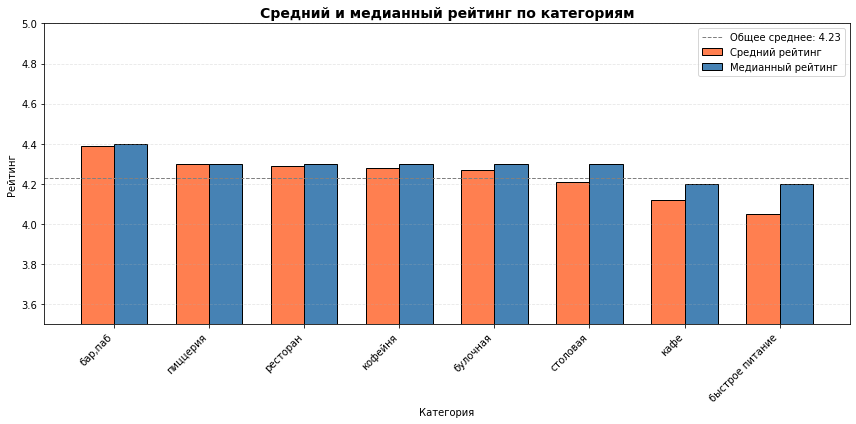

In [85]:
# ВИЗУАЛИЗАЦИЯ СРАВНЕНИЯ КАТЕГОРИЙ (ДОПОЛНИТЕЛЬНАЯ)
top_by_count = data['category'].value_counts().head(8).index
rating_by_cat = (
    data[data['category'].isin(top_by_count)]
    .groupby('category')['rating']
    .agg(['mean', 'median'])
    .round(2)
    .sort_values('mean', ascending=False)
)

fig, ax = plt.subplots(figsize=(12, 6))
x = range(len(rating_by_cat))
width = 0.35

ax.bar([i - width/2 for i in x], rating_by_cat['mean'], width,
       label='Средний рейтинг', color='coral', edgecolor='black')
ax.bar([i + width/2 for i in x], rating_by_cat['median'], width,
       label='Медианный рейтинг', color='steelblue', edgecolor='black')

ax.set_xticks(list(x))
ax.set_xticklabels(rating_by_cat.index, rotation=45, ha='right')
ax.set_title('Средний и медианный рейтинг по категориям', fontsize=14, fontweight='bold')
ax.set_xlabel('Категория')
ax.set_ylabel('Рейтинг')
ax.set_ylim(3.5, 5.0)
ax.axhline(y=rating_stats['mean'], color='gray', linestyle='--', linewidth=1,
           label=f'Общее среднее: {rating_stats["mean"]:.2f}')
ax.legend()
ax.grid(axis='y', alpha=0.3, linestyle='--')
plt.tight_layout()
plt.show()

**Итоговые выводы по анализу рейтингов:**

1. ОБЩАЯ СТАТИСТИКА:
- Средний рейтинг по всем заведениям: 4.23
- Медианный рейтинг: 4.30
- Большинство заведений (55,8%) имеют рейтинг в диапазоне 4.10–4.40

2. РАЗЛИЧИЯ МЕЖДУ КАТЕГОРИЯМИ:
- Рейтинги очень близки между собой
- Разница между максимальным и минимальным средним рейтингом: 0.34
- Стандартное отклонение средних рейтингов: 0.11

3. ЛУЧШИЕ И ХУДШИЕ КАТЕГОРИИ:
- Самый высокий средний рейтинг: бар,паб (4.39)
- Самый низкий средний рейтинг: быстрое питание (4.05)

4. НАБЛЮДЕНИЯ:
- Все категории имеют средний рейтинг выше 4.0 (минимальный — 4.05 у быстрого питания)
- Наблюдается сильная вариация рейтингов внутри категорий: стандартное отклонение внутри категорий (0.34–0.57, в среднем 0.43) в несколько раз превышает разброс между средними рейтингами категорий (0.11)

---

### Задача 6

***Изучите, с какими данными показывают самую сильную корреляцию рейтинги заведений? Постройте и визуализируйте матрицу корреляции рейтинга заведения с разными данными: его категория, положение (административный район Москвы), статус сетевого заведения, количество мест, ценовая категория и признак, является ли заведения круглосуточным. Выберите самую сильную связь и проверьте её.***

In [86]:
# ПОДГОТОВКА ДАННЫХ ДЛЯ PHI_K АНАЛИЗА

# Создаем копию данных для корреляционного анализа
corr_data = data[['rating', 'category', 'district', 'chain', 'seats', 'price', 'is_24_7']].copy()

In [87]:
# ПОДГОТОВКА КАТЕГОРИАЛЬНЫХ ПРИЗНАКОВ

corr_data['category'] = corr_data['category'].astype('category')
corr_data['district'] = corr_data['district'].astype('category')
corr_data['chain'] = corr_data['chain'].astype('category')
corr_data['price'] = corr_data['price'].astype('category')
corr_data['is_24_7'] = corr_data['is_24_7'].astype('category')

In [88]:
# РАСЧЕТ PHI_K МАТРИЦЫ КОРРЕЛЯЦИИ

phi_k_matrix = corr_data.phik_matrix()
phi_k_matrix.round(3)

interval columns not set, guessing: ['rating', 'seats']


,rating,category,district,chain,seats,price,is_24_7
rating,1.000,0.199,0.189,0.119,0.000,0.262,0.161
category,0.199,1.000,0.175,0.266,0.049,0.567,0.245
district,0.189,0.175,1.000,0.064,0.352,0.203,0.076
chain,0.119,0.266,0.064,1.000,0.057,0.218,0.043
seats,0.000,0.049,0.352,0.057,1.000,0.065,0.043
price,0.262,0.567,0.203,0.218,0.065,1.000,0.084
is_24_7,0.161,0.245,0.076,0.043,0.043,0.084,1.000


In [89]:
# АНАЛИЗ СВЯЗИ С РЕЙТИНГОМ

corr_with_rating = phi_k_matrix['rating'].drop('rating').sort_values(ascending=False)
corr_with_rating

price       0.262056
category    0.198739
district    0.189453
is_24_7     0.161010
chain       0.118857
seats       0.000000
Name: rating, dtype: float64

⚠️ Корреляция 0.2621 является слабой

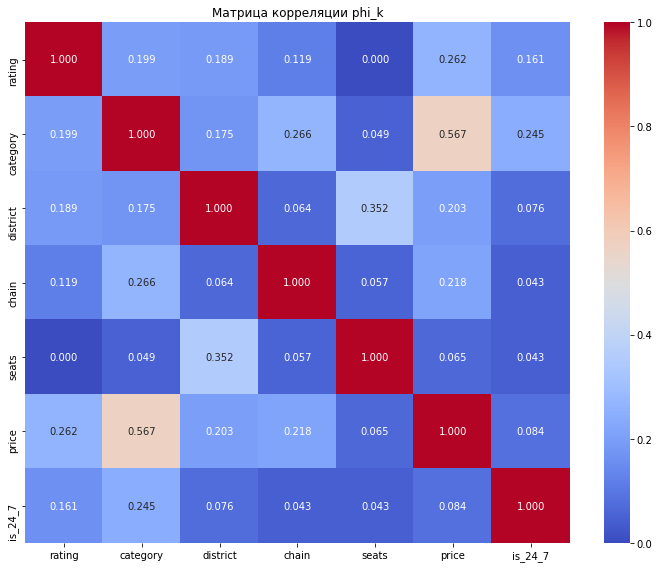

In [90]:
# ВИЗУАЛИЗАЦИЯ МАТРИЦЫ КОРРЕЛЯЦИИ

plt.figure(figsize=(10, 8))
sns.heatmap(phi_k_matrix.astype(float), annot=True, fmt='.3f', cmap='coolwarm', vmin=0, vmax=1)
plt.title('Матрица корреляции phi_k')
plt.tight_layout()
plt.show()

In [91]:
# ДЕТАЛЬНЫЙ АНАЛИЗ ЛУЧШЕГО ПРИЗНАКА

price_stats = data.groupby('price')['rating'].agg(['count', 'mean', 'median', 'std']).round(2)
price_stats

,count,mean,median,std
price,,,,
высокие,478,4.44,4.4,0.31
выше среднего,564,4.39,4.4,0.22
низкие,156,4.17,4.2,0.37
средние,2117,4.30,4.3,0.30


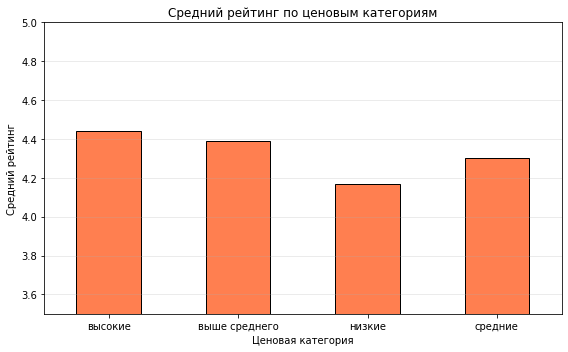

In [92]:
# ДОПОЛНИТЕЛЬНАЯ ВИЗУАЛИЗАЦИЯ ДЛЯ PRICE

price_stats['mean'].plot(kind='bar', figsize=(8, 5), color='coral', edgecolor='black')
plt.title('Средний рейтинг по ценовым категориям')
plt.xlabel('Ценовая категория')
plt.ylabel('Средний рейтинг')
plt.xticks(rotation=0)
plt.ylim(3.5, 5.0)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

📌 ОСНОВНЫЕ ВЫВОДЫ:

1. Наиболее сильная связь с рейтингом обнаружена у признака `price` (ценовая категория).
2. Значение phi_k коэффициента: 0.26 — слабая связь.
3. Остальные признаки связаны с рейтингом ещё слабее: категория (0.20), район (0.19), круглосуточность (0.16), сетевость (0.12), количество мест (0.00).

Интерпретация:
- Связь рейтинга с ценовой категорией слабая, но заметная: средний рейтинг монотонно растёт от низких ценовых категорий (4.17) к высоким (4.44). Это логично: дорогие заведения обычно предлагают более высокий уровень обслуживания и качество продукта.
- Медианные значения рейтинга для категорий «выше среднего» и «высокие» равны (4.4) при сопоставимом количестве оценок (564 и 478 заведений). При этом средние различаются (4.39 и 4.44), то есть в премиум-сегменте чуть больше заведений с высокими оценками, но типичный (медианный) уровень лояльности одинаков. Это значит, что при прочих равных за меньшие деньги можно получить такую же типичную лояльность покупателей, как и в премиум-сегменте.

4. Практические рекомендации:
- При выборе формата заведения ценовую категорию можно учитывать, но не делать её определяющим фактором.
- Ценовая политика связана с рейтингом, но не определяет его (связь слабая).
- Ключевые факторы успеха — качество продукта и обслуживание.
- В любой ценовой категории можно достичь высокого рейтинга при правильном подходе.

---

### Задача 7

***Сгруппируйте данные по названиям заведений и найдите топ-15 популярных сетей в Москве. Для них посчитайте значения среднего рейтинга. Под популярностью понимается количество заведений этой сети в регионе. К какой категории заведений они относятся? Результат сопроводите подходящими визуализациями.***

In [93]:
# ФИЛЬТРАЦИЯ СЕТЕВЫХ ЗАВЕДЕНИЙ И ГРУППИРОВКА ПО НАЗВАНИЯМ И КАТЕГОРИЯМ

chain_data = data[data['chain'] == 1].copy()

network_stats = (
    chain_data.groupby(['name', 'category'])
    .agg(Количество_заведений=('name', 'count'), Средний_рейтинг=('rating', 'mean'))
    .reset_index()
    .rename(columns={'name': 'Название_сети', 'category': 'Категория'})
    .sort_values('Количество_заведений', ascending=False)
)

top_15_networks = network_stats.head(15).copy()
top_15_networks['Средний_рейтинг'] = top_15_networks['Средний_рейтинг'].round(2)
top_15_networks['Количество_заведений'] = top_15_networks['Количество_заведений'].astype(int)

In [94]:
top_15_networks

,Название_сети,Категория,Количество_заведений,Средний_рейтинг
1126,шоколадница,кофейня,119,4.18
496,домино'с пицца,пиццерия,76,4.17
489,додо пицца,пиццерия,74,4.29
205,one price coffee,кофейня,71,4.06
1142,яндекс лавка,ресторан,69,3.87
72,cofix,кофейня,65,4.08
241,prime,ресторан,49,4.11
617,кофепорт,кофейня,42,4.15
632,кулинарная лавка братьев караваевых,кафе,39,4.39
963,теремок,ресторан,36,4.11


In [95]:
# СТАТИСТИКА ПО ТОП-15 СЕТЯМ

total_chain_in_top = top_15_networks['Количество_заведений'].sum()
pd.DataFrame({
    'Показатель': ['Заведений в топ-15', 'Доля от сетевых, %', 'Доля от всех, %',
                   'Средний рейтинг топ-15', 'Мин. рейтинг', 'Макс. рейтинг'],
    'Значение': [
        total_chain_in_top,
        round(total_chain_in_top / len(chain_data) * 100, 1),
        round(total_chain_in_top / len(data) * 100, 1),
        round(top_15_networks['Средний_рейтинг'].mean(), 2),
        top_15_networks['Средний_рейтинг'].min(),
        top_15_networks['Средний_рейтинг'].max()
    ]
})

,Показатель,Значение
0,Заведений в топ-15,768.00
1,"Доля от сетевых, %",24.00
2,"Доля от всех, %",9.10
3,Средний рейтинг топ-15,4.15
4,Мин. рейтинг,3.87
5,Макс. рейтинг,4.46


In [96]:
top_15_networks['Категория'].value_counts()

кофейня     6
кафе        3
ресторан    3
пиццерия    2
булочная    1
Name: Категория, dtype: int64

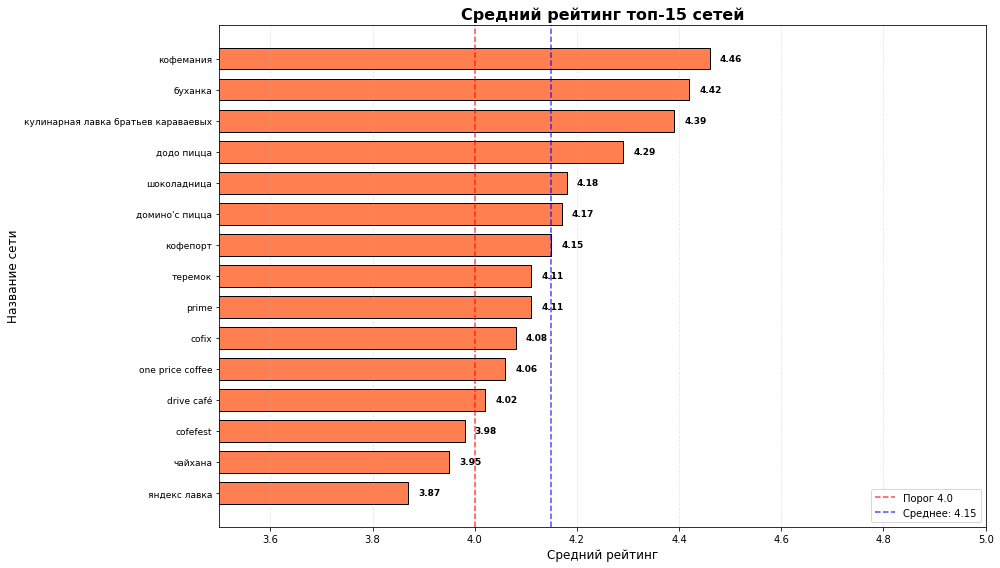

In [97]:
# ВИЗУАЛИЗАЦИЯ ТОП-15 СЕТЕЙ

# Создаем фигуру только с одним графиком
fig, ax = plt.subplots(figsize=(14, 8))

# ГРАФИК: Средний рейтинг топ-15 сетей (горизонтальный)

# Сортируем данные по среднему рейтингу для горизонтального отображения (сверху - самые высокие)
top_by_rating = top_15_networks.sort_values('Средний_рейтинг', ascending=True)

# Создаем горизонтальную столбчатую диаграмму
y_pos = np.arange(len(top_by_rating))
bars = ax.barh(y_pos, top_by_rating['Средний_рейтинг'].values,
               color='coral', edgecolor='black', height=0.7)

# Настраиваем подписи оси Y
ax.set_yticks(y_pos)
ax.set_yticklabels(top_by_rating['Название_сети'].values, fontsize=9)

# Добавляем заголовки и подписи
ax.set_title('Средний рейтинг топ-15 сетей', fontsize=16, fontweight='bold')
ax.set_xlabel('Средний рейтинг', fontsize=12)
ax.set_ylabel('Название сети', fontsize=12)

# Добавляем вертикальные линии
ax.axvline(x=4.0, color='red', linestyle='--', linewidth=1.5, alpha=0.7, label='Порог 4.0')
ax.axvline(x=top_15_networks['Средний_рейтинг'].mean(), color='blue', linestyle='--', 
           linewidth=1.5, alpha=0.7, label=f"Среднее: {top_15_networks['Средний_рейтинг'].mean():.2f}")
ax.legend(loc='lower right', fontsize=10)

# Добавляем значения на столбцы (справа от каждого столбца)
for i, (idx, row) in enumerate(top_by_rating.iterrows()):
    ax.text(row['Средний_рейтинг'] + 0.02, i, 
            f"{row['Средний_рейтинг']:.2f}", 
            ha='left', va='center', fontsize=9, fontweight='bold')

# Добавляем сетку для лучшей читаемости
ax.grid(axis='x', alpha=0.3, linestyle='--')

# Устанавливаем границы оси X для лучшей визуализации
ax.set_xlim(3.5, 5.0)

plt.tight_layout()
plt.show()

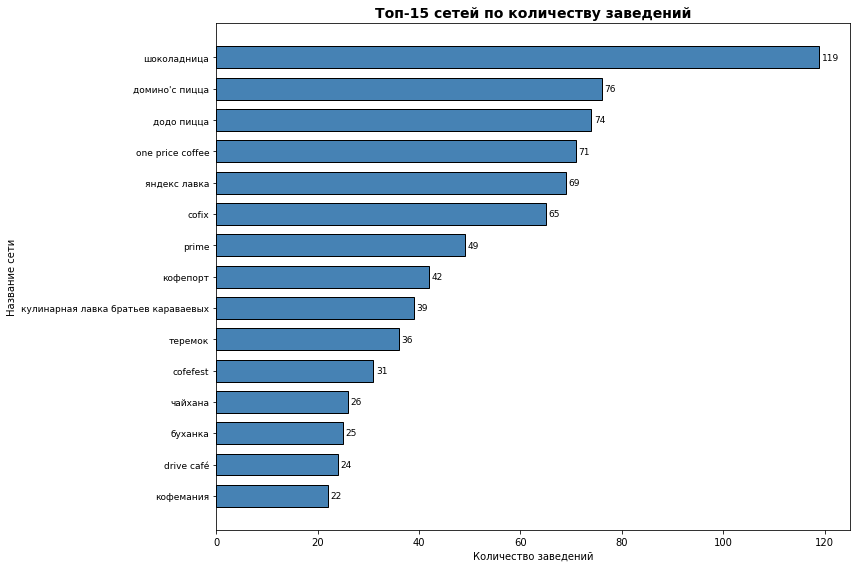

In [98]:
# Топ-15 по количеству заведений
fig, ax = plt.subplots(figsize=(12, 8))

top_by_count = top_15_networks.sort_values('Количество_заведений', ascending=True)
y_pos = np.arange(len(top_by_count))
bars = ax.barh(y_pos, top_by_count['Количество_заведений'].values,
               color='steelblue', edgecolor='black', height=0.7)

ax.set_yticks(y_pos)
ax.set_yticklabels(top_by_count['Название_сети'].values, fontsize=9)
ax.set_title('Топ-15 сетей по количеству заведений', fontsize=14, fontweight='bold')
ax.set_xlabel('Количество заведений')
ax.set_ylabel('Название сети')

# Добавляем значения
for i, (idx, row) in enumerate(top_by_count.iterrows()):
    ax.text(row['Количество_заведений'] + 0.5, i, 
             str(row['Количество_заведений']), 
             ha='left', va='center', fontsize=9)

plt.tight_layout()
plt.show()

**Промежуточные выводы**

1. СЕТЕВЫЕ ЗАВЕДЕНИЯ:
- Всего сетевых заведений: 3203 (38,1% от всех заведений)
- Всего уникальных сетей: 747

2. ТОП-15 ПОПУЛЯРНЫХ СЕТЕЙ:
- Самая популярная сеть: «Шоколадница» (119 заведений)
- Средний рейтинг топ-15 сетей: 4.15
- Сеть с самым высоким рейтингом: «Кофемания» (4.46)
- Сеть с самым низким рейтингом: «Яндекс Лавка» (3.87)

3. КАТЕГОРИИ В ТОП-15 СЕТЯХ:
- Преобладающая категория: кофейня (6 сетей, 40,0%)
- кафе: 3 сети (20,0%)
- ресторан: 3 сети (20,0%)
- пиццерия: 2 сети (13,3%)
- булочная: 1 сеть (6,7%)

---

### Задача 8

***Изучите вариацию среднего чека заведения (столбец `middle_avg_bill`) в зависимости от района Москвы. Проанализируйте цены в Центральном административном округе и других. Как удалённость от центра влияет на цены в заведениях? Результат сопроводите подходящими визуализациями.***


In [99]:
# Анализ статистических показателей
data['middle_avg_bill'].describe()

count     3149.000000
mean       958.053650
std       1009.732849
min          0.000000
25%        375.000000
50%        750.000000
75%       1250.000000
max      35000.000000
Name: middle_avg_bill, dtype: float64

In [100]:
# Удаляем 3 явных выброса (10 000+ ₽) — они не влияют на медиану, но искажают среднее и графики
bill_data = data[data['middle_avg_bill'] < 10000]
bill_data['middle_avg_bill'].describe()

count    3146.000000
mean      941.166870
std       770.527771
min         0.000000
25%       375.000000
50%       750.000000
75%      1250.000000
max      7250.000000
Name: middle_avg_bill, dtype: float64

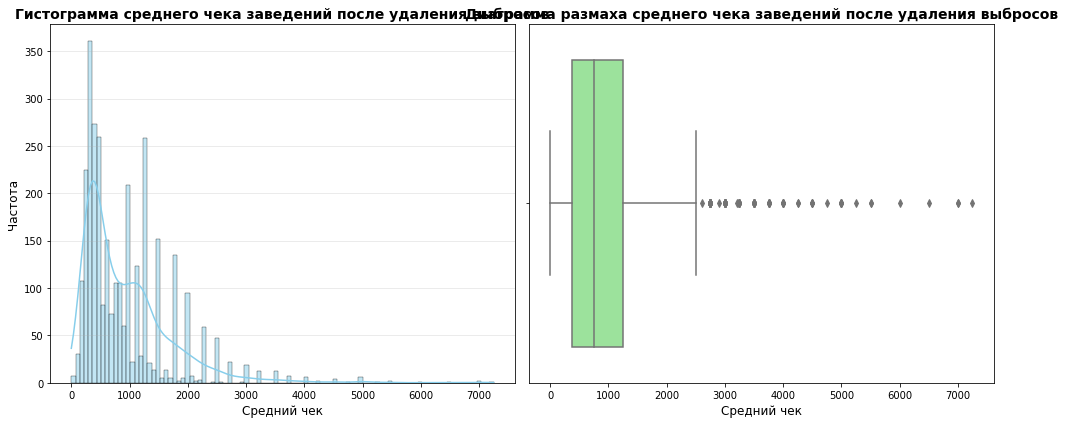

In [101]:
# Визуализация: Гистограмма после удаления выбросов
plt.figure(figsize=(14, 6))

# Гистограмма
plt.subplot(1, 2, 1)
sns.histplot(bill_data['middle_avg_bill'], bins=100, kde=True, color='skyblue')
plt.title('Гистограмма среднего чека заведений после удаления выбросов', fontsize=14, fontweight='bold')
plt.xlabel('Средний чек', fontsize=12)
plt.ylabel('Частота', fontsize=12)
plt.grid(axis='y', alpha=0.3)

# Диаграмма размаха
plt.subplot(1, 2, 2)
sns.boxplot(x=bill_data['middle_avg_bill'], color='lightgreen')
plt.title('Диаграмма размаха среднего чека заведений после удаления выбросов', fontsize=14, fontweight='bold')
plt.xlabel('Средний чек', fontsize=12)

plt.tight_layout()
plt.show()

In [102]:
# ОБЩИЙ АНАЛИЗ ДАННЫХ О СРЕДНЕМ ЧЕКЕ

avg_bill_data = bill_data[bill_data['middle_avg_bill'].notna()].copy()
avg_bill_data['middle_avg_bill'].describe()

count    3146.000000
mean      941.166870
std       770.527771
min         0.000000
25%       375.000000
50%       750.000000
75%      1250.000000
max      7250.000000
Name: middle_avg_bill, dtype: float64

In [103]:
# ФУНКЦИЯ ПРЕОБРАЗОВАНИЯ НАЗВАНИЙ ДЛЯ КОРРЕКТНОГО ОТОБРАЖЕНИЯ НА ГРАФИКЕ

def shorten_district_name(district_name):
    if pd.isna(district_name):
        return district_name
    return district_name.replace('административный округ', 'АО').strip()

sorted(district_counts.rename(index=shorten_district_name).index)

['Восточный АО',
 'Западный АО',
 'Северный АО',
 'Северо-Восточный АО',
 'Северо-Западный АО',
 'Центральный АО',
 'Юго-Восточный АО',
 'Юго-Западный АО',
 'Южный АО']

In [104]:
# Проверяем наличие данных о среднем чеке
avg_bill_data['district_short'] = avg_bill_data['district'].apply(shorten_district_name)
district_counts = avg_bill_data['district_short'].value_counts()

# Создаем словарь для замены названий в district_counts
# Применяем сокращения ко всем индексам в district_counts
district_short = district_counts.rename(index=shorten_district_name)

In [105]:
# СРАВНЕНИЕ ЦЕНТРАЛЬНОГО АО С ДРУГИМИ РАЙОНАМИ

cao_bill_data = avg_bill_data[avg_bill_data['district_short'] == 'Центральный АО']
other_bill_data = avg_bill_data[avg_bill_data['district_short'] != 'Центральный АО']

cao_bill_stats = cao_bill_data['middle_avg_bill'].describe()
other_bill_stats = other_bill_data['middle_avg_bill'].describe()

pd.DataFrame({'ЦАО': cao_bill_stats, 'Другие районы': other_bill_stats}).round(0)

,ЦАО,Другие районы
count,1060.0,2086.0
mean,1191.0,814.0
std,920.0,646.0
min,0.0,30.0
25%,500.0,350.0
50%,1000.0,600.0
75%,1500.0,1150.0
max,7250.0,5500.0


In [106]:
# Рассчитываем статистику по среднему чеку для каждого района
district_bill_stats = (
    avg_bill_data.groupby('district_short')['middle_avg_bill']
    .agg(Средний_чек='mean', Медианный_чек='median', Количество='count', Стандартное_отклонение='std')
    .round(0)
    .sort_values('Средний_чек', ascending=False)
)
district_bill_stats.head(10)

,Средний_чек,Медианный_чек,Количество,Стандартное_отклонение
district_short,,,,
Центральный АО,1191.0,1000.0,1060,920.0
Западный АО,1053.0,1000.0,306,779.0
Северный АО,897.0,650.0,321,719.0
Северо-Западный АО,822.0,700.0,157,595.0
Юго-Западный АО,793.0,600.0,235,559.0
Восточный АО,785.0,550.0,259,632.0
Южный АО,725.0,500.0,313,543.0
Северо-Восточный АО,717.0,500.0,301,591.0
Юго-Восточный АО,654.0,450.0,194,567.0


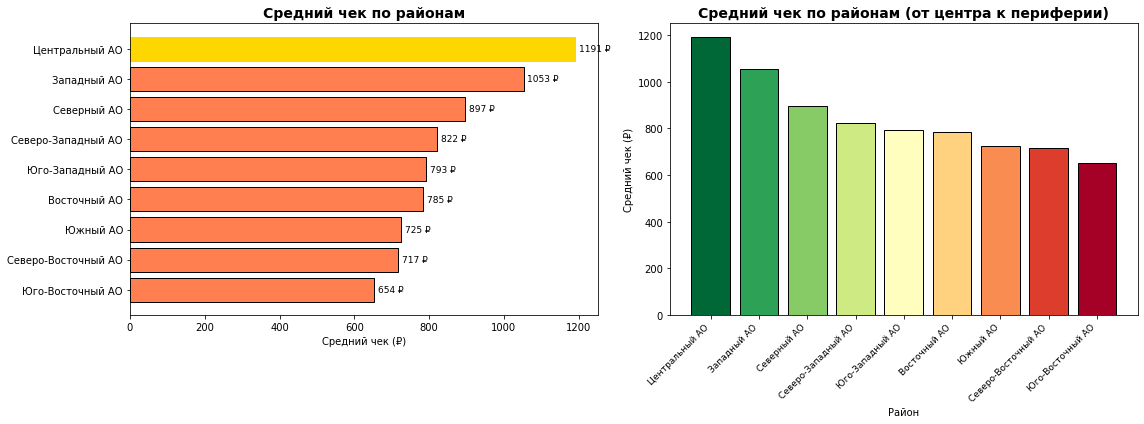

In [107]:
# ВИЗУАЛИЗАЦИЯ

# Создаем фигуру с двумя графиками (1 строка, 2 столбца)
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# ГРАФИК 1: Средний чек по районам
ax1 = axes[0]
top_districts = district_bill_stats.head(9)
top_districts_sorted = top_districts.sort_values('Средний_чек', ascending=True)
bars1 = ax1.barh(range(len(top_districts_sorted)), 
                  top_districts_sorted['Средний_чек'].values,
                  color='coral', edgecolor='black')
ax1.set_yticks(range(len(top_districts_sorted)))
ax1.set_yticklabels(top_districts_sorted.index, fontsize=10)
ax1.set_title('Средний чек по районам', fontsize=14, fontweight='bold')
ax1.set_xlabel('Средний чек (₽)')

# Добавляем значения
for i, (idx, row) in enumerate(top_districts_sorted.iterrows()):
    ax1.text(row['Средний_чек'] + 10, i, f"{int(row['Средний_чек'])} ₽", 
             va='center', fontsize=9)

# Выделяем ЦАО цветом
for i, (idx, row) in enumerate(top_districts_sorted.iterrows()):
    if idx == 'Центральный АО':
        bars1[i].set_color('gold')

# ГРАФИК 3: Зависимость среднего чека от удаленности от центра
ax2 = axes[1]

# Сортируем районы по среднему чеку (предполагаем, что это коррелирует с удаленностью от центра)
district_order = district_bill_stats.sort_values('Средний_чек', ascending=False).index
x_pos = np.arange(len(district_order))
colors_distance = plt.cm.RdYlGn_r(np.linspace(0, 1, len(district_order)))  # Красный - центр, зеленый - периферия

bars2 = ax2.bar(x_pos, district_bill_stats.loc[district_order, 'Средний_чек'].values,
                color=colors_distance, edgecolor='black')
ax2.set_xticks(x_pos)
ax2.set_xticklabels(district_order, rotation=45, ha='right', fontsize=9)
ax2.set_title('Средний чек по районам (отсортировано по убыванию)', 
              fontsize=14, fontweight='bold')
ax2.set_xlabel('Район')
ax2.set_ylabel('Средний чек (₽)')

# Добавляем линию тренда

plt.tight_layout()
plt.show()

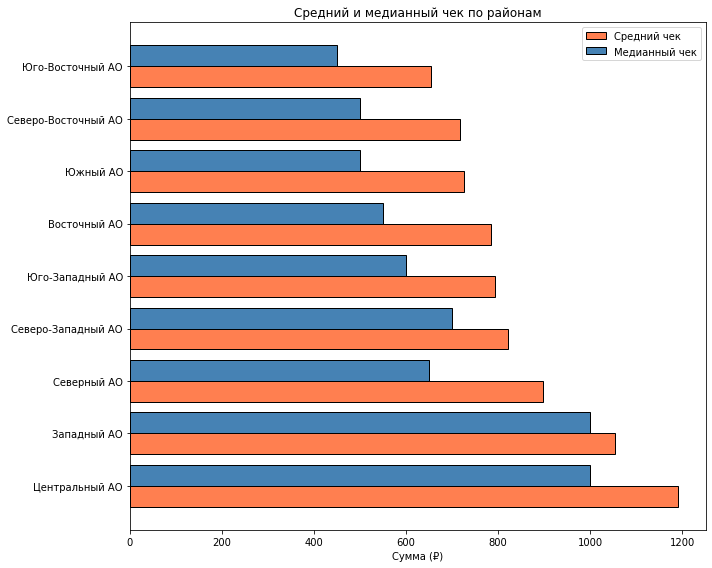

In [108]:
# ГРАФИК 2: Сравнение медианных и средних значений среднего чека по районам
fig, ax = plt.subplots(figsize=(10, 8))
y = np.arange(len(district_bill_stats))
height = 0.4

ax.barh(y - height/2, district_bill_stats['Средний_чек'], height,
        label='Средний чек', color='coral', edgecolor='black')
ax.barh(y + height/2, district_bill_stats['Медианный_чек'], height,
        label='Медианный чек', color='steelblue', edgecolor='black')

ax.set_yticks(y)
ax.set_yticklabels(district_bill_stats.index)
ax.set_xlabel('Сумма (₽)')
ax.set_title('Средний и медианный чек по районам')
ax.legend()
plt.tight_layout()
plt.show()

In [109]:
# ДОПОЛНИТЕЛЬНЫЙ АНАЛИЗ: РАСПРЕДЕЛЕНИЕ ЦЕН ПО КАТЕГОРИЯМ В ЦАО

cao_category_bill = (
    cao_bill_data.groupby('category')['middle_avg_bill']
    .agg(Количество='count', Средний_чек='mean', Медиана='median')
    .round(0)
    .sort_values('Медиана', ascending=False)
)
cao_category_bill.head(10)

,Количество,Средний_чек,Медиана
category,,,
"бар,паб",173,1480.0,1250.0
ресторан,406,1561.0,1250.0
пиццерия,81,1105.0,1000.0
булочная,12,1238.0,962.0
кафе,210,765.0,700.0
кофейня,85,795.0,500.0
быстрое питание,49,532.0,450.0
столовая,44,320.0,300.0


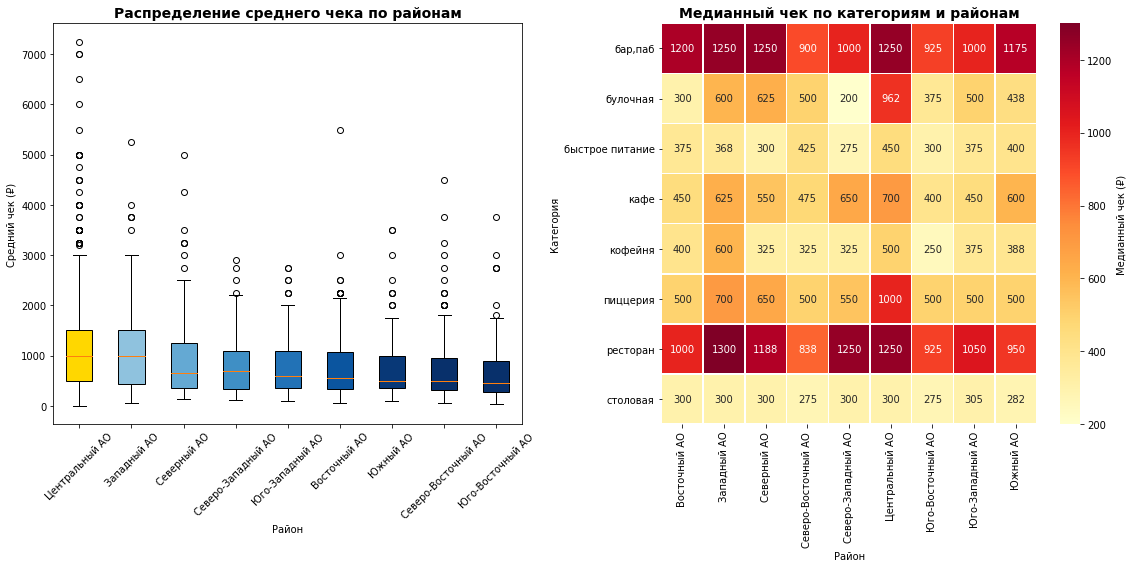

In [110]:
# Распределение чека по районам и категориям

fig, axes = plt.subplots(1, 2, figsize=(16, 8))

# График 1: Ящики с усами для всех районов (топ-10 по количеству данных)
ax1 = axes[0]
# Берем районы с достаточным количеством данных
districts_with_enough_data = district_bill_stats[district_bill_stats['Количество'] > 10].head(10).index
box_data_districts = [avg_bill_data[avg_bill_data['district_short'] == d]['middle_avg_bill'].dropna().values 
                      for d in districts_with_enough_data]

bp = ax1.boxplot(box_data_districts, labels=districts_with_enough_data, patch_artist=True)
ax1.set_title('Распределение среднего чека по районам', fontsize=14, fontweight='bold')
ax1.set_xlabel('Район')
ax1.set_ylabel('Средний чек (₽)')
ax1.tick_params(axis='x', rotation=45)

# Раскрашиваем ящики (ЦАО выделяем)
for i, (patch, district) in enumerate(zip(bp['boxes'], districts_with_enough_data)):
    if district == 'Центральный АО':
        patch.set_facecolor('gold')
    else:
        patch.set_facecolor(plt.cm.Blues(0.3 + i/len(districts_with_enough_data)))

# График 2: Тепловая карта цен по районам и категориям
ax2 = axes[1]
# Создаем сводную таблицу средних чеков по районам и категориям
pivot_table = pd.pivot_table(
    avg_bill_data, 
    values='middle_avg_bill', 
    index='category', 
    columns='district_short',
    aggfunc='median',
    fill_value=0
)

# Берем топ-10 категорий по районам
top_categories = avg_bill_data['category'].value_counts().head(8).index
top_districts = avg_bill_data['district_short'].value_counts().head(9).index

heatmap_data = pivot_table.loc[
    pivot_table.index.isin(top_categories), 
    pivot_table.columns.isin(top_districts)
]

sns.heatmap(heatmap_data, annot=True, fmt='.0f', cmap='YlOrRd', 
            linewidths=0.5, cbar_kws={'label': 'Медианный чек (₽)'}, ax=ax2)
ax2.set_title('Медианный чек по категориям и районам', fontsize=14, fontweight='bold')
ax2.set_xlabel('Район')
ax2.set_ylabel('Категория')

plt.tight_layout()
plt.show()

In [111]:
# СТАТИСТИЧЕСКАЯ ПРОВЕРКА РАЗЛИЧИЙ

cao_cv = cao_bill_stats['std'] / cao_bill_stats['mean'] * 100
other_cv = other_bill_stats['std'] / other_bill_stats['mean'] * 100
print(f'CV в ЦАО: {cao_cv:.1f}%, CV в других районах: {other_cv:.1f}%')

CV в ЦАО: 77.2%, CV в других районах: 79.4%


In [112]:
# Статистика по среднему чеку: Москва, ЦАО, другие районы
bill_stats = avg_bill_data['middle_avg_bill'].describe()
cao_bill_stats = cao_bill_data['middle_avg_bill'].describe()
other_bill_stats = other_bill_data['middle_avg_bill'].describe()

diff_mean = cao_bill_stats['mean'] - other_bill_stats['mean']
diff_percent = diff_mean / other_bill_stats['mean'] * 100

In [113]:
# Сохраняем основные результаты в DataFrame для дальнейшего использования
results = pd.DataFrame({
    'Показатель': ['Средний чек по Москве', 'Медианный чек по Москве',
                   'Средний чек в ЦАО', 'Медианный чек в ЦАО',
                   'Средний чек в других районах', 'Медианный чек в других районах',
                   'Разница (ЦАО - другие)', 'Разница в %'],
    'Значение': [f"{bill_stats['mean']:.0f} ₽", f"{bill_stats['50%']:.0f} ₽",
                 f"{cao_bill_stats['mean']:.0f} ₽", f"{cao_bill_stats['50%']:.0f} ₽",
                 f"{other_bill_stats['mean']:.0f} ₽", f"{other_bill_stats['50%']:.0f} ₽",
                 f"{diff_mean:.0f} ₽", f"{diff_percent:.1f}%"]
})

results

,Показатель,Значение
0,Средний чек по Москве,941 ₽
1,Медианный чек по Москве,750 ₽
2,Средний чек в ЦАО,1191 ₽
3,Медианный чек в ЦАО,1000 ₽
4,Средний чек в других районах,814 ₽
5,Медианный чек в других районах,600 ₽
6,Разница (ЦАО - другие),377 ₽
7,Разница в %,46.3%


**Промежуточные выводы**

1. ОБЩАЯ КАРТИНА:
- Средний чек по Москве: 941 ₽
- Медианный чек: 750 ₽

2. ЦЕНТРАЛЬНЫЙ АО:
- Средний чек: 1191 ₽
- Медианный чек: 1000 ₽

3. ДРУГИЕ РАЙОНЫ:
- Средний чек варьируется от 654 ₽ (ЮВАО) до 1053 ₽ (ЗАО)
- Наиболее дорогие районы после ЦАО: Западный АО (1053 ₽) и Северный АО (897 ₽)
- Наиболее доступные районы: Юго-Восточный АО (654 ₽), Северо-Восточный АО (717 ₽) и Южный АО (725 ₽)

4. ВЛИЯНИЕ УДАЛЁННОСТИ ОТ ЦЕНТРА:
- ЦАО — самый дорогой округ: средний чек здесь на 46,3% выше, чем в остальных районах (1191 ₽ против 814 ₽).
- Среди остальных округов явного градиента «центр → периферия» не наблюдается: разница между округами невелика (654–1053 ₽), и порядок районов по цене не соответствует их географическому положению.

5. РАЗБРОС ЦЕН:
- Разброс цен в ЦАО и других районах сопоставим: коэффициент вариации 77,2% в ЦАО и 79,4% в остальных районах.

---

### Общий вывод


**1. Анализ по категориям**
- На категории кафе, ресторан и кофейня приходится 69,4% заведений Москвы (28,3%, 24,3% и 16,8% соответственно).

**2. Анализ по административным районам**
- 2242 заведения (26,7% от общего количества) составляют заведения ЦАО.
- На долю САО, ЮАО, СВАО и ЗАО приходится от 10,1% до 10,7%. На остальные округа — 31,3%.
- В ЦАО 29,9% заведений приходится на рестораны, 20,7% — на кафе, 19,1% — на кофейни, 16,2% — на бары и пабы.

**3. Анализ по сетевому фактору**
- Доля сетевых заведений составляет 38,1% от общего количества.
- В процентном соотношении среди сетевых заведений преобладают булочные (61,3%), пиццерии (52,1%) и кофейни (51,0%).
- В абсолютном количестве среди сетевых преобладают кафе (779), рестораны (729) и кофейни (720).
- Наибольшая доля сетевых заведений — в ЗАО (44,2%).

**4. Анализ по посадочным местам**
- Данные искажены значениями, которые не соответствуют реальности. Если требуются более точные значения, стоит дополнительно определить, как относить заведения на фудкортах и в других специфических местах.
- С учётом указанного факта среднее количество мест по всем заведениям составляет 108,4 при медиане 75.
- Для всех категорий медианное количество мест находится в диапазоне 50–86.
- Самые «компактные» категории — булочные (50), пиццерии (55) и кафе (60).

**5. Анализ по рейтингу заведений**
- Средний рейтинг по всем заведениям составляет 4,23 при медиане 4,30.
- Самые высокие рейтинги характерны для баров и пабов (4,39), самые низкие — для фастфуда (4,05).
- Внутри категорий наблюдается сильная вариация: стандартное отклонение внутри категорий (0,43) в несколько раз превышает разброс между средними рейтингами категорий (0,11).

**6. Анализ по взаимосвязям данных с рейтингом заведений**
- Наиболее сильная связь с рейтингом — у ценовой категории `price`, но она слабая (phi_k = 0,26).
- Средний рейтинг монотонно растёт с ценой: от 4,17 в низких категориях до 4,44 в высоких. Дешёвые цены характерны для фастфуда, дорогие — для баров и пабов.

**7. Анализ по популярным сетям**
- Всего в Москве представлено 747 уникальных сетей.
- Наиболее популярные сети — «Шоколадница» (с большим отрывом), «Домино'с пицца», «Додо пицца», «One price coffee», «Яндекс Лавка», «Cofix».
- Самый высокий рейтинг среди сетей у «Кофемании» (4.46), самый низкий — у «Яндекс Лавки» (3.87). У лидера по количеству заведений «Шоколадницы» — 4,18.
- В топ-15 сетей преобладают категории кофеен и кафе.

**8. Анализ по вариации среднего чека**
- Средний чек в ЦАО составляет 1191 ₽ при 941 ₽ по Москве (медианные значения 1000 ₽ и 750 ₽ соответственно).
- Средний чек по районам варьируется от 654 ₽ (ЮВАО) до 1053 ₽ (ЗАО).
- Наиболее «дорогие» районы после центра — Западный АО (1053 ₽) и Северный АО (897 ₽). Самые доступные — ЮВАО (654 ₽), СВАО (717 ₽) и ЮАО (725 ₽).
- ЦАО — самый дорогой округ: средний чек здесь на 46,3% выше, чем в остальных районах. При этом среди остальных округов явного градиента «центр → периферия» не наблюдается.
- Разброс цен в ЦАО и других районах сопоставим: коэффициент вариации 77,2% и 79,4% соответственно.

## Итоговый вывод и рекомендации

**1. Общий обзор проделанной работы**

В ходе исследовательского анализа данных было изучено 8402 заведения общественного питания Москвы. Проведена комплексная оценка рынка по ключевым параметрам: категории заведений, географическое распределение, сетевой фактор, посадочные места, рейтинги, ценовые категории, средний чек и популярные сети.


**2. Главные выводы**

- *Структура рынка*
  - Доминирующие форматы: кафе, рестораны и кофейни составляют 69,4% всех заведений Москвы, формируя основу рынка.
  - Концентрация в центре: в Центральном административном округе (ЦАО) сосредоточено 26,7% всех заведений (2242 объекта). При этом в ЦАО преобладают рестораны (29,9%), кафе (20,7%) и кофейни (19,1%).
  - Распределение по другим округам: Северный, Южный, Северо-Восточный и Западный округа имеют равномерную долю (10,1–10,7% каждый), остальные округа в сумме дают 31,3%.

- *Сетевой фактор*
  - Доля сетевых заведений составляет 38,1% рынка.
  - Лидеры по сетевости: булочные (61,3%), пиццерии (52,1%) и кофейни (51,0%) имеют наибольший процент сетевых заведений.
  - Абсолютные лидеры: кафе (779), рестораны (729) и кофейни (720) лидируют по количеству сетевых объектов.
  - Самый сетевой округ: Западный АО (44,2% сетевых заведений).

- *Посадочные места*
  - Среднее количество мест — 108, медианное — 75 (более показательная величина из-за выбросов).
  - Компактные форматы: булочные (медиана 50), пиццерии (55) и кафе (60) имеют наименьшее количество посадочных мест.
  - Важное замечание: данные могут быть искажены заведениями на фудкортах, что требует уточнения при выборе конкретного формата.

- *Рейтинги и их взаимосвязи*
  - Средний рейтинг по Москве — 4,23 (медиана 4,30).
  - Лидеры по рейтингу: бары и пабы (4,39).
  - Аутсайдеры: фастфуд (4,05).
  - Ключевая корреляция: слабая прямая связь между ценовой категорией и рейтингом (phi_k = 0,26) — в среднем чем выше цена, тем выше рейтинг. Корреляция рейтинга с другими признаками ещё слабее (0,00–0,20), что указывает на комплексную природу оценки заведений посетителями.

- *Популярные сети*
  - В Москве представлено 747 уникальных сетей.
  - Абсолютный лидер: «Шоколадница» (с большим отрывом по количеству заведений, рейтинг 4,18).
  - Топ-сети: «Домино'с пицца», «Додо пицца», «One price coffee», «Яндекс Лавка», «Cofix».
  - Самый высокий рейтинг: у сети «Кофемания» (4,46), самый низкий — у «Яндекс Лавки» (3,87).
  - В топ-15 сетей преобладают кофейни и кафе, подтверждая популярность этих форматов.

- *Ценовой анализ*
  - Средний чек в ЦАО составляет 1191 ₽ против 941 ₽ в среднем по Москве (медианы: 1000 ₽ и 750 ₽ соответственно).
  - Градация по цене:
    - Самые дорогие округа после центра: ЗАО (1053 ₽) и САО (897 ₽).
    - Самые доступные: ЮВАО (654 ₽), СВАО (717 ₽) и ЮАО (725 ₽).
  - ЦАО — самый дорогой округ: средний чек здесь на 46,3% выше, чем в остальных районах. При этом среди остальных округов явного градиента «центр → периферия» не наблюдается.
  - Разброс цен в ЦАО и других районах сопоставим: коэффициент вариации 77,2% и 79,4% соответственно, что не даёт оснований говорить о «значительно большем разбросе» на периферии.

**3. Рекомендации на основе анализа данных**

    3.1 Выбор локации: стратегия "Центр vs Периферия"

| Параметр | Центр (ЦАО) | Периферия |
|:---------|:-----------:|:---------:|
| **Целевая аудитория** | Туристы, офисные сотрудники, высокодоходная аудитория | Местные жители, семейная аудитория |
| **Средний чек** | Высокий (факт: средний 1191 ₽, медиана 1000 ₽; рекомендация: 1200–1500 ₽) | Средний/низкий (факт: средний 814 ₽, медиана 600 ₽; рекомендация: 650–1000 ₽) |
| **Конкуренция** | Очень высокая (26,7% всех заведений Москвы) | Умеренная (4,9–10,7% на округ) |
| **Рекомендуемые форматы** | Рестораны, бары, специализированные кофейни | Кафе, семейные рестораны, демократичные форматы |

    3.2 Выбор категории заведения

| Формат | Сильные стороны | Слабые стороны | Рекомендации |
|:-------|:---------------:|:--------------:|:-------------|
| **Кофейня** | Высокая оборачиваемость, сетевой потенциал (51,0% сетевых), компактность | Высокая конкуренция в центре (19,1% заведений ЦАО) | Оптимальна для спальных районов и локаций с высоким трафиком; медиана посадочных мест — 80 |
| **Кафе** | Универсальность, стабильный спрос | Высокая конкуренция во всех районах (28,3% всех заведений Москвы) | Хороший выбор для округов с равномерной плотностью населения |
| **Ресторан** | Высокий средний чек, престижность | Сложность управления, высокие риски | В ЦАО (38,3% заведений округа) или крупных ТЦ при уникальной концепции |
| **Бар/Паб** | Высокие рейтинги (4,39 — 1-е место), лояльная аудитория | Зависимость от вечернего трафика | Перспективно в ЦАО (16,3% против 11,1% по Москве) и районах с развитой инфраструктурой |
| **Фастфуд** | Высокая оборачиваемость | Низкие рейтинги (4,05 — последнее место), конкуренция с сетевыми игроками (43,0% сетевых) | Требует уникального предложения или строгого соблюдения стандартов сети |

    3.3 Ценовое позиционирование

- Для ЦАО: средний чек 1200–1500 ₽ с фокусом на качество и уникальность. Фактический средний чек в ЦАО — 1191 ₽, медиана — 1000 ₽; рекомендация предполагает позиционирование чуть выше рынка.
- Для ЗАО: средний чек 1000–1300 ₽. Фактический средний чек — 1053 ₽, медиана — 1000 ₽.
- Для спальных районов: средний чек 700–900 ₽ с акцентом на соотношение цены и качества. Фактический средний чек по остальным районам — 814 ₽, медиана — 600 ₽; рекомендация — в верхней половине диапазона.
- Универсальная стратегия: использовать дифференциацию меню (утренние/дневные/вечерние предложения) для максимизации выручки.

    3.4 Сетевая стратегия

- Для одиночного заведения: выбирать форматы с низкой сетевой плотностью (бары — 9,1% по Москве, рестораны с уникальной концепцией) или форматы с умеренной долей сетевых, где есть пространство для одиночного игрока (кафе — 32,8% сетевых), при условии высокого качества. Кофейни менее пригодны для одиночного входа: 51,0% из них уже сетевые.
- Для сети: рассмотреть форматы кофеен (51,0% сетевых — доказанная масштабируемость) или кафе (32,8% — есть потенциал роста).
- ЗАО — наиболее насыщенный сетями округ (44,2%), что говорит о высокой конкуренции с сетями. Для выхода с уникальной концепцией могут быть интересны округа с меньшей сетевой плотностью.
- Наиболее зарекомендовавшая себя сеть по количеству заведений — «Шоколадница» (119 заведений, рейтинг 4,18).
- Сеть с самым высоким рейтингом — «Кофемания» (4,46).

**4. Итоговые рекомендации**

- *Оптимальный формат для инвестиций:* кофейня или кафе как наиболее сбалансированные по спросу, рентабельности и потенциалу масштабирования форматы. Кафе — самая массовая категория (28,3% всех заведений), кофейни — третья (16,8%) и наполовину сетевые (51,0%), что подтверждает их масштабируемость.

- *Локация «Золотая середина»:* Западный АО сочетает высокий средний чек (1053 ₽, медиана 1000 ₽), высокую сетевую структуру (44,2% сетевых) и относительно умеренную конкуренцию по сравнению с центром (26,7% всех заведений — в ЦАО).

- *Для эконом-сегмента:* ЮВАО (8,5% всех заведений, средний чек 654 ₽) и СЗАО (4,9%, средний чек 822 ₽) — менее насыщенные рынки с низким средним чеком, где можно занять нишу качественного демократичного общепита. СВАО (10,6%, 717 ₽) — также доступный округ, но с более высокой конкуренцией.

- *Ключевой фактор успеха:* учитывая слабую корреляцию рейтинга с объективными параметрами (phi_k ≤ 0,26), решающее значение имеют сервис, качество продукции и атмосфера. Это подтверждается высокими рейтингами небольших специализированных проектов — «Кофемания» (4,46), «Буханка» (4,42) и др.

**Заключение:** 

***Московский рынок общепита предлагает возможности для различных форматов и бюджетов. Наиболее перспективным представляется открытие кафе или кофейни в Западном или Северном округах со средним чеком 900-1100 ₽, либо демократичного заведения в ЮВАО со средним чеком 650-750 ₽ при фокусе на качество и локальную аудиторию.***